# Машинное обучение, ФКН ВШЭ

## Практическое домашнее задание 3. Генерация признаков

### Общая информация

Дата выдачи: 19.10.2025

Мягкий дедлайн: 04.11.2025 23:59MSK

Жесткий дедлайн: 08.11.2025 23:59MSK

### О задании

В данном задании необходимо реализовать самые ходовые техники для создания новых признаков в табличном машинном обучении. Вам понадобиться применить всю вашу фантазию, чтобы собрать наилучшие признаки для решения задачи линейной классификации и победы в соревновании

### Оценивание и штрафы

Каждая из задач имеет определенную «стоимость» (указана в скобках около задачи). Максимально допустимая оценка за работу — 11 баллов. Детальнее про оценивание — в самом конце ноутбука.

Сдавать задание после указанного срока сдачи нельзя. При выставлении неполного балла за задание в связи с наличием ошибок на усмотрение проверяющего предусмотрена возможность исправить работу на указанных в ответном письме условиях.

Задание выполняется самостоятельно. «Похожие» решения считаются плагиатом и все задействованные студенты (в том числе те, у кого списали) не могут получить за него больше 0 баллов (подробнее о плагиате см. на странице курса). Если вы нашли решение какого-то из заданий (или его часть) в открытом источнике, необходимо указать ссылку на этот источник в отдельном блоке в конце вашей работы (скорее всего вы будете не единственным, кто это нашел, поэтому чтобы исключить подозрение в плагиате, необходима ссылка на источник).

Неэффективная реализация кода может негативно отразиться на оценке. Также оценка может быть снижена за плохо читаемый код и плохо считываемые диаграммы.

Все ответы должны сопровождаться кодом или комментариями о том, как они были получены.

### Формат сдачи
Задания сдаются через систему Anytask. Инвайт можно найти на странице курса. Присылать необходимо ноутбук с выполненным заданием. Сам ноутбук называйте в формате **homework-practice-03-features-Username.ipynb**, где Username — ваша фамилия.

Для удобства проверки самостоятельно посчитайте свою максимальную оценку (исходя из набора решенных задач) и укажите ниже.

**Оценка**: ...

### **Задание 1. Вводная часть (1 балл)** <img align="center" height=25 src="https://media.tenor.com/5vGX5VO-IxsAAAAi/arthas.gif">

<img style="float: right; padding-right:10px" src="https://media.discordapp.net/attachments/674191702906503199/1429321721495949392/pomoika2.png?ex=68f5b715&is=68f46595&hm=f6664e6068c19ab5606c40ca6ef92c093cb343b8b96c471c3d8927dc4569552c&=&format=webp&quality=lossless&width=432&height=648" height=400></img>
    
В этом домашнем задании мы будем работать с датасетом по широко известной в неузких кругах видеоигре Dota 2. Если вы не знакомы с ней - ничего страшного, все необходимое для задания мы подробно опишем. Также, как ни странно, не стесняйтесь спрашивать у гугла, гпт или, прости Господи, дотеров, если вам что-то не ясно.

Подробное описание данных настолько большое, что описано отдельно на страничке соревнования.

Очень краткое описание игры:
- Dota 2 - это командная игра, в которой принимает участие 5 игроков со стороны Radiant и 5 игроков со стороны Dire;
- каждый из игроков выбирает своего героя, все герои в одной игре разные, у каждого героя есть ряд атрибутов, которые сильно отличают его от других;
- цель игроков - снести главную постройку вражеской стороны (в простонародье - трон);
- игроки могут зарабатывать деньги, убивать персонажей вражеской команды, чтобы становиться сильнее и легче снести этот самый трон;
- игра всегда заканчивается победой одной стороны, может идти от 0 минут до бесконечности.

Мы будем пытаться предсказать исход матча - победа или поражение, исходя из разных факторов, с которыми мы познакомимлся ниже. По задумке мы пытаемся предсказать матчи, которые едва начались (например, чтобы делать ставки на спорт), поэтому ряд данных на тестовой выборке отсутствует. Целевая метрика уже выбрана за нас: мы будем считать ROC-AUC, но не простой, а коэффициент Джини, чтобы избегать странных значений метрики меньше $0.5$:

$$ \text{Gini} = | 2 \cdot \text{ROCAUC} - 1 |$$

#### **Важнейшее замечание!!!**

Предполагается, что у вас уже сложилось понимание:
- как крутить и вертеть данные, чтобы все трансформы ложились четко, все шейпы датафреймов стакались, все нужные джойны джойнились;
- когда ваша модель хуже или лучше, как это проверять и как подбирать гиперпараметры (валидация - наш лучший друг, иногда даже лучше настоящих);
- на какой выборке делать `fit`, а на какой `transform`, чтобы не допустить утечки данных;
- как базово кодировать признаки, чтобы ваша модель вообще обучалась (без нормализации никуда, если используем регуляризацию, категории обязательно кодируем);
- как рисовать читаемые графики.

Пожалуйста, следите за этим очень-очень внимательно, иначе рискуете получить штраф и всеобщее порицание в нашем уютном МО-1 чатике (хотя, может это и неплохо).

> Мы верим, что вы уже достаточно взрослые и самостоятельные, чтобы верно принимать жизненные решения, поэтому большая часть этой домашки не имеет четких критериев успеха, кроме факта выполненного задания.

> Максимум за эту часть домашки — 8 баллов; чтобы добить оставшиеся, вам придется посоревноваться с вашими любимыми сокурсниками.

> Впрочем, для победы в соревновании вам может понадобиться сделать все из них и, скорее всего, даже больше.

> То, насколько эти задания вам помогут, зависит исключительно от вас: какие-то преобразования признаков заходят лучше, какие-то хуже, но гарантируется, что каждое из них может помочь.

> Вы вольны делать любые пункты, которые вам больше нравятся. Для этого мы прикладываем схему, которую желательно изучить, прежде чем приступать к выполнению задания.

<img src="https://i.postimg.cc/K8qYFHyv/image-2025-10-19-164454599.png"></img>

In [1]:
from sklearn.metrics import roc_auc_score
from typing import Optional, Callable


def gini(y_true, y_score):
    return abs(2 * roc_auc_score(y_true, y_score) - 1.0)

#### Задание 1.1. Знакомство с данными (0.5 балла)

Чтобы начать работу с данными, эти данные сперва нужно загрузить. В рамках этого ноутбука нам потребуются:

1. Информация о матчах - `matches_df_train.csv`.
2. Информация об игроках - `player_df.csv`.
3. Информация о героях - `Constants.Heroes.csv`.
4. Информация о статистиках матча - `dota_adv.csv`.
5. Тестовые данные для соревнования - `matches_df_test.csv`.

Дополнительные данные, при остром желании, можно попробовать стащить [отсюда](https://www.kaggle.com/datasets/bwandowando/dota-2-pro-league-matches-2023), но в обязательную часть это не входит.

Первое задание максимально скучное:

1. Посмотрите на все датафреймы выше - какие в них колонки, по какому признаку их можно джойнить между собой, на типы и тд.
2. Проверьте, есть ли в данных пропуски, дубли, выбросы, и хотите ли вы что-то с ними сделать.
3. Разбейте данные на трейн и валидацию (доля разбиения - на ваше усмотрение).
4. Найдите, где же наш таргет, и постройте график его распределения на трейне и валидации.
5. Сделайте вывод: подходящая ли в данном случае метрика Gini? Аргументируйте ваш ответ.

#### 1.

In [2]:
import pandas as pd
import numpy as np

train = pd.read_csv("dota-2-hse-ml-1-course-competition-2025/matches_df_train.csv", index_col=False)
test = pd.read_csv("dota-2-hse-ml-1-course-competition-2025/matches_df_test.csv", index_col=False)
players_df = pd.read_csv("dota-2-hse-ml-1-course-competition-2025/player_df.csv", index_col=False)
match_stats = pd.read_csv("dota-2-hse-ml-1-course-competition-2025/dota_adv.csv", index_col=False)
game_heroes = pd.read_csv("dota-2-hse-ml-1-course-competition-2025/Constants.Heroes.csv", index_col=False)

In [153]:
train.head(10)

,match_id,date,region,game_mode,duration,radiant_win
0,1606558457,2024-01-01,3,1,50,True
1,1533104773,2024-01-01,3,1,86,True
2,1494396881,2024-01-01,3,1,211,True
3,1457581060,2024-01-01,3,1,270,True
4,1590242915,2024-01-01,3,21,318,True
5,1605768990,2024-01-01,4,1,332,True
6,1541196419,2024-01-01,12,21,358,True
7,1486558998,2024-01-01,3,1,372,True
8,1415399699,2024-01-01,3,3,379,True
9,1518009122,2024-01-01,9,21,420,True


In [154]:
train['game_mode'].unique()

array([ 1, 21,  3,  8, 22,  2,  4, 20, 18, 12,  5, 13, 16, 11])

In [155]:
train['region'].unique()

array([ 3,  4, 12,  9,  6, 11,  2, 10,  5,  1,  8,  7])

In [156]:
test.head(10)

,match_id,date,region,game_mode
0,1509410699,2024-12-14,6,22
1,1307322096,2024-12-15,12,22
2,1427032882,2024-12-03,3,1
3,1335981501,2024-12-29,3,1
4,1305100719,2024-12-23,3,22
5,1449801929,2024-12-09,4,1
6,1577714339,2024-12-15,3,1
7,1388830129,2024-12-15,4,1
8,1380311439,2024-12-17,3,22
9,1585811696,2024-12-28,11,1


In [157]:
players_df.head(10)

,player_slot,account_id,hero_id,kills,deaths,assists,gold,last_hits,denies,gold_per_min,xp_per_min,hero_damage,tower_damage,match_id
0,130,10111871,5,3.0,8.0,15.0,2971.0,55.0,3.0,291.0,390.0,7431.0,146.0,1411590681
1,130,43341844,3,3.0,9.0,3.0,1245.0,25.0,3.0,238.0,346.0,4187.0,34.0,1388958799
2,130,72157343,53,9.0,6.0,20.0,4544.0,226.0,1.0,583.0,704.0,9406.0,2375.0,1587246664
3,1,4294967295,17,21.0,3.0,15.0,2945.0,209.0,12.0,577.0,641.0,30957.0,1801.0,1490278157
4,2,54350942,19,9.0,8.0,8.0,413.0,227.0,9.0,471.0,584.0,18215.0,627.0,1526223166
5,0,33392751,112,9.0,7.0,10.0,718.0,111.0,4.0,357.0,342.0,7537.0,591.0,1527074624
6,2,107611476,44,8.0,3.0,10.0,1021.0,253.0,5.0,545.0,666.0,11769.0,2627.0,1610660217
7,129,60618584,12,4.0,7.0,9.0,3974.0,356.0,6.0,520.0,614.0,13667.0,4069.0,1611993826
8,1,171813327,27,4.0,7.0,18.0,2968.0,31.0,3.0,324.0,459.0,6006.0,1762.0,1374583150
9,0,56921537,72,12.0,4.0,12.0,5580.0,220.0,11.0,648.0,619.0,14485.0,1734.0,1541610095


In [158]:
players_df["hero_id"].unique()

array([  5,   3,  53,  17,  19, 112,  44,  12,  27,  72,  71,  21,  75,
        60,  67,  36,  65,   7,  80,  31,  34,  15,   6,  74,  45,  30,
        35,  54, 110, 104, 105,  22,  25,  32,  66,   2,  50,  62,  64,
        42,  47,  29, 111,  56,  20,  11,   4,  26, 102, 100,  10,  93,
        49,  41,  70,  86,  97,  14,  96,  85,  88,   8,  57,  39, 101,
        40,  95,  69,  73,  94,  87,  52,  79,  51,   1,   9,  23, 109,
        59,  99,  81,  84,  43,  89,  63,  18,  90, 107,  98,  46,  58,
        13,  16, 106,  38,  78,  28,  83,  82,  77, 103,  68,  61,  92,
        91,  37,  55,  48,  33,  76,   0])

In [3]:
game_heroes = game_heroes[["id", "name", "primary_attr", "attack_type", "roles", "base_health", "base_health_regen"]]
# game_heroes = game_heroes.drop(columns=['Unnamed: 0', 'img', 'icon', 'localized_name', 'str_gain'])
game_heroes.head(10)

,id,name,primary_attr,attack_type,roles,base_health,base_health_regen
0,1,npc_dota_hero_antimage,agi,Melee,"['Carry', 'Escape', 'Nuker']",120,1.00
1,2,npc_dota_hero_axe,str,Melee,"['Initiator', 'Durable', 'Disabler', 'Carry']",120,2.50
2,3,npc_dota_hero_bane,all,Ranged,"['Support', 'Disabler', 'Nuker', 'Durable']",120,0.25
3,4,npc_dota_hero_bloodseeker,agi,Melee,"['Carry', 'Disabler', 'Nuker', 'Initiator']",120,0.25
4,5,npc_dota_hero_crystal_maiden,int,Ranged,"['Support', 'Disabler', 'Nuker']",120,0.25
5,6,npc_dota_hero_drow_ranger,agi,Ranged,"['Carry', 'Disabler', 'Pusher']",120,0.25
6,7,npc_dota_hero_earthshaker,str,Melee,"['Support', 'Initiator', 'Disabler', 'Nuker']",120,1.00
7,8,npc_dota_hero_juggernaut,agi,Melee,"['Carry', 'Pusher', 'Escape']",120,0.50
8,9,npc_dota_hero_mirana,all,Ranged,"['Carry', 'Support', 'Escape', 'Nuker', 'Disab...",120,0.25
9,10,npc_dota_hero_morphling,agi,Ranged,"['Carry', 'Escape', 'Durable', 'Nuker', 'Disab...",120,0.50


In [160]:
game_heroes.columns

Index(['id', 'name', 'primary_attr', 'attack_type', 'roles', 'base_health',
       'base_health_regen'],
      dtype='object')

In [161]:
match_stats.head(10)

,match_id,radiant_gold_adv,radiant_exp_adv
0,1340959379,[],[]
1,1377521758,[],[]
2,1457973639,[],[]
3,1629821522,[],[]
4,1529300845,[ 0 334 179 655 31 1029 1029 1029 662 ...,[ 0 147 105 -9 -651 -471 -471 -7...
5,1374585443,[],[]
6,1284028822,[],[]
7,1445909917,[],[]
8,1462542634,[],[]
9,1529771794,[ 0 -602 -487 -981 -906 -470 -470 -608 -431 ...,[ 0 -62 -491 -280 -412 586 586 586 104 ...


In [162]:
print(players_df.shape)
print(train.shape)
print(test.shape)
print(game_heroes.shape)

(7650825, 14)
(706880, 6)
(60954, 4)
(126, 7)


In [163]:
print(match_stats.dtypes)
print(players_df.dtypes)
print(train.dtypes)

match_id             int64
radiant_gold_adv    object
radiant_exp_adv     object
dtype: object
player_slot       int64
account_id        int64
hero_id           int64
kills           float64
deaths          float64
assists         float64
gold            float64
last_hits       float64
denies          float64
gold_per_min    float64
xp_per_min      float64
hero_damage     float64
tower_damage    float64
match_id          int64
dtype: object
match_id        int64
date           object
region          int64
game_mode       int64
duration        int64
radiant_win      bool
dtype: object


In [164]:
print(game_heroes.dtypes)

id                     int64
name                  object
primary_attr          object
attack_type           object
roles                 object
base_health            int64
base_health_regen    float64
dtype: object


#### 2.

In [165]:
for df,name in [(train,"train"), (test,"test"), (players_df,"players_df"), (match_stats, "match_stats"), (game_heroes, "game_heroes")]:
    s = df.isna().sum()
    s = s[s>0].sort_values(ascending=False)
    print(f"\nПропуски в {name}:\n", s)


Пропуски в train:
 Series([], dtype: int64)

Пропуски в test:
 Series([], dtype: int64)

Пропуски в players_df:
 kills           607494
deaths          607494
assists         607494
gold            607494
last_hits       607494
denies          607494
gold_per_min    607494
xp_per_min      607494
hero_damage     607494
tower_damage    607494
dtype: int64

Пропуски в match_stats:
 Series([], dtype: int64)

Пропуски в game_heroes:
 base_health_regen    1
dtype: int64


In [ ]:
game_heroes['base_health_regen'] = game_heroes['base_health_regen'].fillna(game_heroes['base_health_regen'].median())

In [261]:
train_match_ids = set(train['match_id'])
test_match_ids = set(test['match_id'])
matches_with_missing = players_df[players_df['kills'].isna()]['match_id'].unique()
missing_in_train = [m for m in matches_with_missing if m in train_match_ids]
missing_in_test = [m for m in matches_with_missing if m in test_match_ids]

print(len(missing_in_train))
print(len(missing_in_test))

1
60953


Большинство пропусков приходится на тестовую выборку, удалять строки test нельзя, удалим один пропуск из train

In [263]:
match_id_to_drop = missing_in_train[0]
train = train[train['match_id'] != match_id_to_drop].copy()
players_df = players_df[players_df['match_id'] != match_id_to_drop].copy()

Проверка

In [256]:
for df,name in [(train,"train"), (test,"test"), (players_df,"players_df"), (match_stats, "match_stats"), (game_heroes, "game_heroes")]:
    s = df.isna().sum()
    s = s[s>0].sort_values(ascending=False)
    print(f"\nПропуски в {name}:\n", s)


Пропуски в train:
 Series([], dtype: int64)

Пропуски в test:
 Series([], dtype: int64)

Пропуски в players_df:
 deaths          607494
assists         607494
gold            607494
last_hits       607494
denies          607494
gold_per_min    607494
xp_per_min      607494
hero_damage     607494
tower_damage    607494
dtype: int64

Пропуски в match_stats:
 Series([], dtype: int64)

Пропуски в game_heroes:
 turn_rate    82
dtype: int64


Дубликаты

In [170]:
for df,name in [(train,"train"), (test,"test"), (players_df,"players_df"), (match_stats, "match_stats"), (game_heroes, "game_heroes")]:
    print(f"Дубликаты в {name}:", df.duplicated().sum())

Дубликаты в train: 7
Дубликаты в test: 1
Дубликаты в players_df: 0
Дубликаты в match_stats: 12
Дубликаты в game_heroes: 0


In [ ]:
train = train.drop_duplicates()
test = test.drop_duplicates()
match_stats = match_stats.drop_duplicates()

При выявлении выбросов можно посмотреть на 
числовые признаки: kills, deaths, assists, gold, last_hits, denies, gold_per_min, xp_per_min, hero_damage, tower_damage

In [54]:
def detect_outliers_iqr(df, column):
    q1 = df[column].quantile(0.25)
    q3 = df[column].quantile(0.75)
    iqr = q3 - q1
    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr
    return df[(df[column] < lower) | (df[column] > upper)]

In [61]:
cols_to_check = ['kills', 'deaths', 'assists', 'gold','last_hits', 'denies', 'gold_per_min','xp_per_min', 'hero_damage', 'tower_damage']
for col in cols_to_check:
    outliers = detect_outliers_iqr(players_df, col)
    print(f"{col}: выбросов {len(outliers)}, процент: {round(len(outliers) / len(players_df) * 100, 3)}, min {players_df[col].min()}, max {players_df[col].max()}, med {players_df[col].median()}")

kills: выбросов 210174, процент: 2.984, min 0.0, max 128.0, med 6.0
deaths: выбросов 77263, процент: 1.097, min 0.0, max 78.0, med 7.0
assists: выбросов 87152, процент: 1.237, min 0.0, max 128.0, med 10.0
gold: выбросов 262128, процент: 3.722, min 0.0, max 65405.0, med 1288.0
last_hits: выбросов 217819, процент: 3.093, min 0.0, max 2000.0, med 104.0
denies: выбросов 335345, процент: 4.761, min 0.0, max 223.0, med 3.0
gold_per_min: выбросов 85750, процент: 1.217, min 0.0, max 2500.0, med 379.0
xp_per_min: выбросов 52066, процент: 0.739, min 0.0, max 2500.0, med 446.0
hero_damage: выбросов 171553, процент: 2.436, min 0.0, max 100000.0, med 10497.0
tower_damage: выбросов 598691, процент: 8.5, min 0.0, max 32477.0, med 526.0


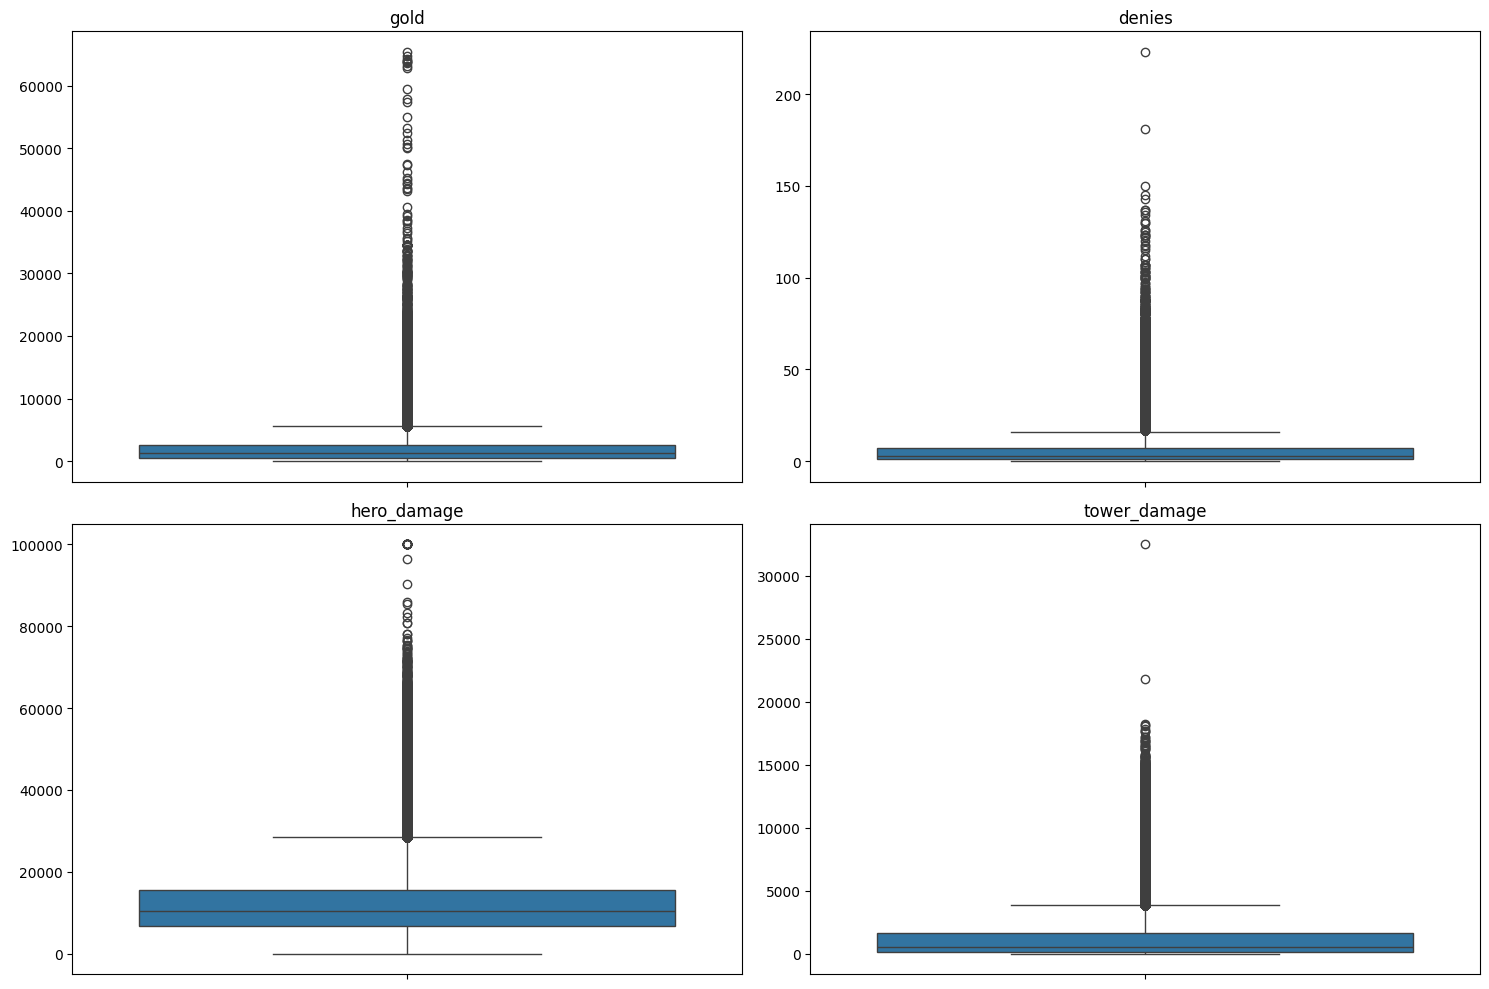

In [9]:
import matplotlib.pyplot as plt
import seaborn as sns

cols_to_plot = ['gold', 'denies', 'hero_damage', 'tower_damage']

fig, axes = plt.subplots(2, 2, figsize=(15, 10))
axes = axes.flatten()

for idx, col in enumerate(cols_to_plot):
    if col in players_df.columns:
        ax = axes[idx]
        
        sns.boxplot(y=players_df[col], ax=ax)
        ax.set_title(f'{col}')
        ax.set_ylabel('')

plt.tight_layout()
plt.show()


Несмотря на большое кол-во выбросов, удалять их не будем, тк они могут быть реальными возможными исходами в игре, далее обработаем их (напр RobustScaler)

Все остальные признаки

In [257]:
game_heroes = game_heroes.rename(columns={'id': 'hero_id'})

In [20]:
categorical_train = ["region", "game_mode"]
numeretic_train = ["duration"]
other_train = ["match_id", "date", "radiant_win"]

numeretic_players = ["kills", "deaths", "assists",	"gold",	"last_hits", "denies", "gold_per_min", "xp_per_min", "hero_damage", "tower_damage"]
other_players = ["player_slot", "account_id", "hero_id", "match_id"]

categorical_heroes = ["name", "primary_attr", "attack_type", "roles"]
numeretic_heroes = ["base_health", "base_health_regen"]
other_heroes = ["hero_id"]

numeretic_stats = ["gold_adv_mean", "gold_adv_max", "gold_adv_min", "gold_adv_last", "gold_adv_std", "exp_adv_mean", "exp_adv_max",	"exp_adv_min", "exp_adv_last", "exp_adv_std"]
other_stats = ["match_id"]


In [21]:
players_full = players_df.merge(game_heroes, on="hero_id")
players_full = players_full.drop(columns=["account_id", "hero_id", "player_slot"])
players_full.head(5)

,kills,deaths,assists,gold,last_hits,denies,gold_per_min,xp_per_min,hero_damage,tower_damage,match_id,name,primary_attr,attack_type,roles,base_health,base_health_regen
0,3.0,8.0,15.0,2971.0,55.0,3.0,291.0,390.0,7431.0,146.0,1411590681,npc_dota_hero_crystal_maiden,int,Ranged,"['Support', 'Disabler', 'Nuker']",120,0.25
1,3.0,9.0,3.0,1245.0,25.0,3.0,238.0,346.0,4187.0,34.0,1388958799,npc_dota_hero_bane,all,Ranged,"['Support', 'Disabler', 'Nuker', 'Durable']",120,0.25
2,9.0,6.0,20.0,4544.0,226.0,1.0,583.0,704.0,9406.0,2375.0,1587246664,npc_dota_hero_furion,int,Ranged,"['Carry', 'Pusher', 'Escape', 'Nuker']",120,0.25
3,21.0,3.0,15.0,2945.0,209.0,12.0,577.0,641.0,30957.0,1801.0,1490278157,npc_dota_hero_storm_spirit,int,Ranged,"['Carry', 'Escape', 'Nuker', 'Initiator', 'Dis...",120,0.50
4,9.0,8.0,8.0,413.0,227.0,9.0,471.0,584.0,18215.0,627.0,1526223166,npc_dota_hero_tiny,str,Melee,"['Carry', 'Nuker', 'Pusher', 'Initiator', 'Dur...",120,2.00


In [193]:
players_full.columns

Index(['kills', 'deaths', 'assists', 'gold', 'last_hits', 'denies',
       'gold_per_min', 'xp_per_min', 'hero_damage', 'tower_damage', 'match_id',
       'name', 'primary_attr', 'attack_type', 'roles', 'base_health',
       'base_health_regen'],
      dtype='object')

In [ ]:
# players_agg["match_id"].nunique()

706466

In [24]:
categorical = categorical_heroes
numeretic = numeretic_players + numeretic_heroes
other = ["match_id"]

In [25]:
from sklearn.preprocessing import OneHotEncoder, RobustScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

column_transformer = ColumnTransformer([
    ("ohe", OneHotEncoder(handle_unknown="ignore", sparse_output=False), categorical),
    ("scaling", RobustScaler(), numeretic),
    ("other", "passthrough", other)
])

players_full_transformed = column_transformer.fit_transform(players_full)

In [26]:
players_full_transformed

array([[0.00000000e+00, 0.00000000e+00, 0.00000000e+00, ...,
        0.00000000e+00, 0.00000000e+00, 1.41159068e+09],
       [0.00000000e+00, 0.00000000e+00, 0.00000000e+00, ...,
        0.00000000e+00, 0.00000000e+00, 1.38895880e+09],
       [0.00000000e+00, 0.00000000e+00, 0.00000000e+00, ...,
        0.00000000e+00, 0.00000000e+00, 1.58724666e+09],
       ...,
       [0.00000000e+00, 0.00000000e+00, 0.00000000e+00, ...,
        0.00000000e+00, 0.00000000e+00, 1.58607133e+09],
       [0.00000000e+00, 0.00000000e+00, 0.00000000e+00, ...,
        0.00000000e+00, 0.00000000e+00, 1.42120639e+09],
       [0.00000000e+00, 0.00000000e+00, 0.00000000e+00, ...,
        0.00000000e+00, 0.00000000e+00, 1.42574683e+09]])

#### 3.

Можно по дате, можно рандомно

In [98]:
train_sorted = train.sort_values("date")

cut_idx = int(len(train_sorted) * 0.8)
train_date = train_sorted.iloc[:cut_idx].reset_index(drop=True)
val_date = train_sorted.iloc[cut_idx:].reset_index(drop=True)

print("train:", train_date.shape, "val:", val_date.shape)


train: (565498, 7) val: (141375, 7)


In [17]:
from sklearn.model_selection import train_test_split

train_rand, val_rand = train_test_split(
    train,
    test_size=0.2,
    stratify=train["radiant_win"],
    random_state=10
)
print("train:", train_rand.shape, "val:", val_rand.shape)

train: (565498, 10) val: (141375, 10)


#### 4.

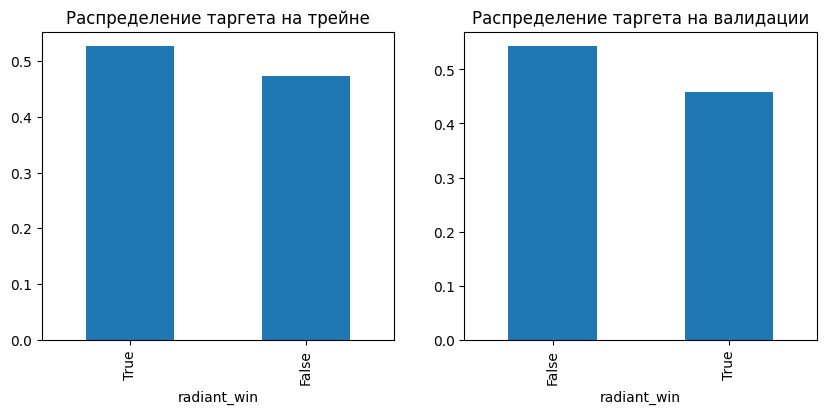

In [100]:
fig, ax = plt.subplots(1, 2, figsize=(10, 4))

train_date["radiant_win"].value_counts(normalize=True).plot(kind="bar", ax=ax[0], title="Распределение таргета на трейне")
val_date["radiant_win"].value_counts(normalize=True).plot(kind="bar", ax=ax[1], title="Распределение таргета на валидации")

plt.show()


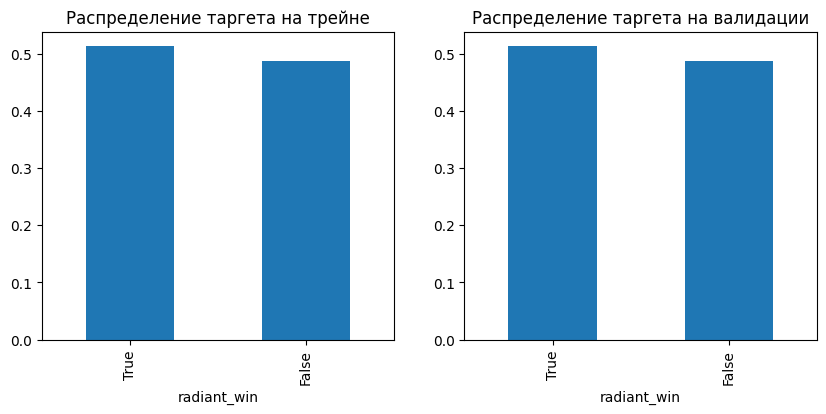

In [101]:
fig, ax = plt.subplots(1, 2, figsize=(10, 4))

train_rand["radiant_win"].value_counts(normalize=True).plot(kind="bar", ax=ax[0], title="Распределение таргета на трейне")
val_rand["radiant_win"].value_counts(normalize=True).plot(kind="bar", ax=ax[1], title="Распределение таргета на валидации")

plt.show()


#### 5.

Метрика Gini подходит, поскольку таргет бинарный, классы распределены довольно сбалансированно (особенно при рандомном сплите)

#### Задание 1.2. Бейзлайн (0.5 балла)

На сей раз мы будем решать задачу классификации, поэтому нам понадобится соответствующая модель. В целом, наши данные уже содержат признаки, по которым что-то даже можно построить.

1. Выберите один или несколько признаков, по которым планируете предсказывать целевую переменную (здесь не нужно придумывать ничего адового, можете даже не делать никаких трансформов, ими мы займемся позже).
2. Выберите модель по вашему вкусу, главное, чтобы она была из `sklearn.linear_model` и не была перцептроном. **Любые другие модели, кроме линейных, запрещены!!!**
3. Обучите модель и замерьте качество.

In [202]:
from sklearn.linear_model import LogisticRegression

baseline_train = train.copy()
categorical = ["region", "game_mode"]
numeretic = ["duration"]
features = baseline_train[categorical + numeretic]
target = baseline_train["radiant_win"]

features_train, features_val, target_train, target_val = train_test_split(features, target,
    test_size=0.2,
    stratify=target,
    random_state=10
)

column_transformer = ColumnTransformer([
    ("ohe", OneHotEncoder(handle_unknown="ignore", sparse_output=False), categorical),
    ("scaling", RobustScaler(), numeretic)
])

model_pipeline = Pipeline(steps=[
    ("preprocess", column_transformer),
    ("clf", LogisticRegression(max_iter=1000, random_state=10))
])

model_pipeline.fit(features_train, target_train)

target_pred = model_pipeline.predict(features_val)
target_pred_proba = model_pipeline.predict_proba(features_val)[:, 1]

acc = gini(target_val, target_pred)
print(f"Gini: {acc:.4f}")

Gini: 0.0412


### **Задание 2. Оптимизация для уже смешариков (2 балла)** <img align="center" src="https://cdn.7tv.app/emote/01H8RPMSBR000133946WK71YXM/1x.avif">

#### Задание 2.1. Optuna для самых маленьких (0.75 балл)

**NB: Хотя это задание и опциональное, выполнить его настоятельно рекомендуется, оно будет очень полезно сейчас, в этой дз, и вообще!**

Не стоит забывать, что у любой модели есть гиперпараметры. Конечно, львиная доля качества будет идти от фичей, но гиперпараметры списывать со счетов тоже не стоит. В конце концов, может быть, что с набором фичей, который считался безперспективным, оптимизированная модель покажет лушее качество, чем модель на топовых фичах, вот и посмотрим.

Оптимизация моделей с большим числом гиперпараметров это сложное дело. Нетрудно догадаться, что в случае, когда параметров $m$, сложность перебора в самом худшем случае будет порядка $n^m$. Подумаем, как это делать умнее.

Для эффективного подбора гиперпараметров существует несколько решений, основанных на байесовской оптимизации. В этом задании предлагается познакомиться с библиотекой [optuna](https://optuna.org/), которая делает перебор гиперпараметров легким и приятным, а также сохраняет всю историю экспериментов в одно место за вас.

Будем разбираться с этим поэтапно.

1. Напишите функцию оптимизации для логистической регрессии. Можете воспользоваться шаблоном ниже, хотя, конечно, это необязательно.
2. Подберите хотя бы 2 гиперпараметра для выбранной вами модели.

LogisticRegression(
penalty='l2',
dual=False, 
tol=0.0001, 
C=1.0, 
fit_intercept=True, 
intercept_scaling=1, 
class_weight=None, 
random_state=None, 
solver='lbfgs', 
max_iter=100, 
multi_class='deprecated', 
verbose=0, 
warm_start=False, 
n_jobs=None, 
l1_ratio=None)

In [204]:
# !pip install optuna

In [205]:
def objective(trial):

    # гипепараметры модели
    model_params = {
        "C": trial.suggest_float("C", 1e-4, 10, log=True),
        "penalty": trial.suggest_categorical("penalty", ["l1", "l2", "elasticnet"]),
        "solver": trial.suggest_categorical("solver", ['lbfgs', 'liblinear', 'newton-cg','newton-cholesky', 'sag', 'saga']),
        "tol": trial.suggest_float("tol", 1e-5, 1e-3, log=True),
        "max_iter": trial.suggest_int("max_iter", 100, 10000, step=500),
        "class_weight": trial.suggest_categorical("class_weight", [None, "balanced"]),
        "random_state": 10
    }

    penalty = model_params["penalty"]
    solver = model_params["solver"]

    valid_combinations = {
        "l1": {"liblinear", "saga"},
        "l2": {"newton-cg", "lbfgs", "liblinear", "sag", "saga"},
        "elasticnet": {"saga"},
    }

    if solver not in valid_combinations[penalty]:
        return -np.inf
    
    if penalty == "elasticnet":
        model_params["l1_ratio"] = trial.suggest_float("l1_ratio", 0.0, 1.0)
        

    # параметры энкодеров, если вы ими пользуетесь
    encoder_params = {
        "categorical": ["region", "game_mode"],
        "numerical": ["duration"]}

    # любые другие параметры, которые вы можете захотеть ввести
    # (e.g. параметры отбора фичей и прочее)
    custom_params = {
        "scaler": RobustScaler(),
        "encoder": OneHotEncoder(handle_unknown="ignore", sparse_output=False)}
    
    column_transformer = ColumnTransformer([
        ("num", custom_params["scaler"], encoder_params["numerical"]),
        ("cat", custom_params["encoder"], encoder_params["categorical"])
    ])

    model_pipeline = Pipeline(steps=[
        ("preprocess", column_transformer),
        ("clf", LogisticRegression(**model_params))
    ])

    model_pipeline.fit(features_train, target_train)
    pred_proba = model_pipeline.predict_proba(features_val)[:, 1]

    gini_valid = gini(target_val, pred_proba)

    return gini_valid

In [206]:
import optuna

study = optuna.create_study(direction="maximize", study_name="logreg_optuna")
study.optimize(objective, n_trials=50, timeout=None)

print("Best trial:")
print("  Gini:", study.best_trial.value)
print("  Params:", study.best_trial.params)

/Users/ssonyii/Downloads/.conda/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
[I 2025-11-03 18:50:17,059] A new study created in memory with name: logreg_optuna
/Users/ssonyii/Downloads/.conda/lib/python3.12/site-packages/optuna/distributions.py:702: UserWarning: The distribution is specified by [100, 10000] and step=500, but the range is not divisible by `step`. It will be replaced by [100, 9600].
  warnings.warn(
[I 2025-11-03 18:50:17,071] Trial 0 finished with value: -inf and parameters: {'C': 0.0004757319251098985, 'penalty': 'l1', 'solver': 'sag', 'tol': 5.457835748378711e-05, 'max_iter': 3100, 'class_weight': 'balanced'}. Best is trial 0 with value: -inf.
[I 2025-11-03 18:50:20,168] Trial 1 finished with value: 0.07707008709548746 and parameters: {'C': 0.00023733674256609002, 'penalty': 'l2', '

Best trial:
  Gini: 0.0776968610721902
  Params: {'C': 0.003678322205738627, 'penalty': 'l2', 'solver': 'lbfgs', 'tol': 1.3909943782046467e-05, 'max_iter': 7100, 'class_weight': 'balanced'}


Убедитесь, что ваша функция работает и модель как минимум работает не хуже, чем без всякого перебора параметров. Качество может вырасти, но очень незначительно, поскольку мы все еще работаем с бейзлайном.

#### Задание 2.2. Логирование в optuna (0.75 балла)

Оптуна - это великая библиотека еще и потому, что сразу предлагает удобный инструментарий для логирования экспериментов.

Посмотрите, как в `optuna` устроена запись в хранилища, и добавьте это в пайплайн оптимизации. Без указания БД все запуски оптуны сотрутся, как только закончится сессия. Более того, так можно распараллелить процесс оптимизации на несколько машин.

Что от вас требуется:
- отдельный `storage`, который сохраняет результаты локально, а не только в рамках одной сессии. В любом удобном для вас виде: хоть датафрейм, хоть БД (в `optuna` для этого есть специальный класс, поищите).
- логирование разных экспериментов с разным именем, чтобы иметь возможность их сравнивать (например, `linreg_base` для бейзлайна регрессии, `logreg_yoba_features_ultrafinal` для самого лучшего логрега, главное, чтобы вам это было понятно и можно было адекватно сравнить перформанс разных моделей, ничего не потеряв).

In [ ]:
optuna_logs = []

def objective(trial):

    # гипепараметры модели
    model_params = {
        "C": trial.suggest_float("C", 1e-4, 10, log=True),
        "penalty": trial.suggest_categorical("penalty", ["l1", "l2", "elasticnet"]),
        "solver": trial.suggest_categorical("solver", ['lbfgs', 'liblinear', 'newton-cg','newton-cholesky', 'sag', 'saga']),
        "tol": trial.suggest_float("tol", 1e-5, 1e-3, log=True),
        "max_iter": trial.suggest_int("max_iter", 100, 10000, step=500),
        "class_weight": trial.suggest_categorical("class_weight", [None, "balanced"]),
        "random_state": 10
    }

    if model_params["penalty"] == "l1" and model_params["solver"] not in ["liblinear", "saga"]:
        raise optuna.TrialPruned()
    if model_params["penalty"] == "elasticnet" and model_params["solver"] != "saga":
        raise optuna.TrialPruned()
    if model_params["penalty"] == "elasticnet":
        model_params["l1_ratio"] = trial.suggest_float("l1_ratio", 0.0, 1.0)
        

    # параметры энкодеров, если вы ими пользуетесь
    encoder_params = {
        "categorical": ["region", "game_mode"],
        "numerical": ["duration"]}

    # любые другие параметры, которые вы можете захотеть ввести
    # (e.g. параметры отбора фичей и прочее)
    custom_params = {
        "scaler": RobustScaler(),
        "encoder": OneHotEncoder(handle_unknown="ignore", sparse_output=False)}
    
    column_transformer = ColumnTransformer([
        ("num", custom_params["scaler"], encoder_params["numerical"]),
        ("cat", custom_params["encoder"], encoder_params["categorical"])
    ])

    model_pipeline = Pipeline(steps=[
        ("preprocess", column_transformer),
        ("clf", LogisticRegression(**model_params))
    ])

    model_pipeline.fit(features_train, target_train)
    pred_proba = model_pipeline.predict_proba(features_val)[:, 1]

    gini_valid = gini(target_val, pred_proba)

    optuna_logs.append({
        **model_params,
        "gini_valid": gini_valid,
        "trial_number": trial.number
    })

    return gini_valid

In [ ]:
study = optuna.create_study(direction="maximize", study_name="logreg_gini_df")
study.optimize(objective, n_trials=30)

results_df = pd.DataFrame(optuna_logs).sort_values("gini_valid", ascending=False)
print(results_df.head())

results_df.to_csv("optuna_baseline_results.csv", index=False)

[I 2025-11-03 19:10:11,154] A new study created in memory with name: logreg_gini_df
[I 2025-11-03 19:10:11,157] Trial 0 pruned. 
[I 2025-11-03 19:10:11,158] Trial 1 pruned. 
[I 2025-11-03 19:10:11,559] Trial 2 finished with value: 0.07756061314746998 and parameters: {'C': 0.6384602216346282, 'penalty': 'l2', 'solver': 'newton-cholesky', 'tol': 2.1933485189614412e-05, 'max_iter': 8100, 'class_weight': None}. Best is trial 2 with value: 0.07756061314746998.
/Users/ssonyii/Downloads/.conda/lib/python3.12/site-packages/optuna/distributions.py:702: UserWarning: The distribution is specified by [100, 10000] and step=500, but the range is not divisible by `step`. It will be replaced by [100, 9600].
  warnings.warn(
[I 2025-11-03 19:10:12,435] Trial 3 finished with value: 0.07757134751325068 and parameters: {'C': 2.445916504139495, 'penalty': 'l2', 'solver': 'liblinear', 'tol': 0.00013551153112196425, 'max_iter': 3100, 'class_weight': None}. Best is trial 3 with value: 0.07757134751325068.
/Us

           C     penalty solver       tol  max_iter class_weight  \
17  0.076200  elasticnet   saga  0.000070      5100         None   
21  0.043124  elasticnet   saga  0.000130      7100         None   
20  0.044994  elasticnet   saga  0.000108      7100         None   
16  0.051764  elasticnet   saga  0.000066      5100         None   
18  0.081662  elasticnet   saga  0.000077      5100         None   

    random_state  gini_valid  trial_number  l1_ratio  
17            10    0.077747            22  0.999746  
21            10    0.077746            28  0.715688  
20            10    0.077745            27  0.765451  
16            10    0.077745            21  0.903848  
18            10    0.077742            23  0.936525  


#### Задание 2.3. Базовый feature selection (0.5 балла)

У любой модели, помимо этапа тюнинга во время обучения, зачастую есть и тюнинг после обучения. Готовы поспорить, что из сотен признаков, что вы потенциально можете нагенерить в данном задании, большинство окажутся вовсе бесполезными. Подробнее с методами feature selection мы познакомимся позже, но уже сейчас мы можем воспользоваться знанием, что к примеру L1-регуляризация может занулять ненужные веса, и что коэффициент у нормированных весов отражает, насколько этот вес важен.

Попробуйте встроить примитивный алгоритм feature selection:
- после обучения модели будем проверять по фиксированной сетке [25%, 50%, 75%, 100%], сколько фичей хотим оставить;
- для каждого значения сетки замеряем качество алгоритма и логгируем в оптуну значение метрики для данного процента фичей;
- для выбора оптимальной модели храним не самое лучшее значение Джини, а самое лучшее значение с учетом оставшегося количества признаков.

In [ ]:
optuna_logs = []

def objective(trial):

    # гипепараметры модели
    model_params = {
        "C": trial.suggest_float("C", 1e-4, 10, log=True),
        "penalty": trial.suggest_categorical("penalty", ["l1", "l2", "elasticnet"]),
        "solver": trial.suggest_categorical("solver", ['lbfgs', 'liblinear', 'newton-cg','newton-cholesky', 'sag', 'saga']),
        "tol": trial.suggest_float("tol", 1e-5, 1e-3, log=True),
        "max_iter": trial.suggest_int("max_iter", 100, 10000, step=500),
        "class_weight": trial.suggest_categorical("class_weight", [None, "balanced"]),
        "random_state": 10
    }

    if model_params["penalty"] == "l1" and model_params["solver"] not in ["liblinear", "saga"]:
        raise optuna.TrialPruned()
    if model_params["penalty"] == "elasticnet" and model_params["solver"] != "saga":
        raise optuna.TrialPruned()
    if model_params["penalty"] == "elasticnet":
        model_params["l1_ratio"] = trial.suggest_float("l1_ratio", 0.0, 1.0)
        

    # параметры энкодеров, если вы ими пользуетесь
    encoder_params = {
        "categorical": ["region", "game_mode"],
        "numerical": ["duration"]}

    # любые другие параметры, которые вы можете захотеть ввести
    # (e.g. параметры отбора фичей и прочее)
    custom_params = {
        "scaler": RobustScaler(),
        "encoder": OneHotEncoder(handle_unknown="ignore", sparse_output=False)}
    
    column_transformer = ColumnTransformer([
        ("num", custom_params["scaler"], encoder_params["numerical"]),
        ("cat", custom_params["encoder"], encoder_params["categorical"])
    ])

    model_pipeline = Pipeline(steps=[
        ("preprocess", column_transformer),
        ("clf", LogisticRegression(**model_params))
    ])

    model_pipeline.fit(features_train, target_train)
    

    pred_proba_full = model_pipeline.predict_proba(features_val)[:, 1]
    gini_full = gini(target_val, pred_proba_full)


    # feature selection
    fractions = [0.25, 0.50, 0.75, 1.00]

    best_gini_score = gini_full
    best_n_features_fraction = 1.0

    if model_params["penalty"] in ["l1", "elasticnet"]:

        feature_names = model_pipeline["preprocess"].get_feature_names_out()
        coefs = model_pipeline["clf"].coef_[0]

        coef_df = pd.DataFrame({
            'feature': feature_names, 
            'importance': np.abs(coefs)
        }).sort_values('importance', ascending=False)

        features_train_processed = model_pipeline["preprocess"].transform(features_train)
        features_val_processed = model_pipeline["preprocess"].transform(features_val)

        for fraction in fractions:
            if fraction == 1.0:
                continue

            n_features = int(len(coef_df) * fraction)
            top_features = coef_df['feature'].iloc[:n_features].tolist()
            indices = [i for i, f in enumerate(feature_names) if f in top_features]

            features_train_fs = features_train_processed[:, indices]
            features_val_fs = features_val_processed[:, indices]

            clf_tmp = LogisticRegression(**model_params)
            clf_tmp.fit(features_train_fs, target_train)
            preds_tmp = clf_tmp.predict_proba(features_val_fs)[:, 1]

            gini_tmp = gini(target_val, preds_tmp)

            if gini_tmp > best_gini_score:
                best_gini_score = gini_tmp
                best_n_features_fraction = fraction


    optuna_logs.append({
        **model_params,
        "gini_full": gini_full,
        "gini_valid": best_gini_score,
        "n_features_fraction": best_n_features_fraction,
        "trial_number": trial.number
    })

    return best_gini_score

In [ ]:
study = optuna.create_study(direction="maximize", study_name="baseline_feature_selection")
study.optimize(objective, n_trials=30, timeout=None)

results_df = pd.DataFrame(optuna_logs).sort_values("gini_valid", ascending=False)
print(results_df.head())

results_df.to_csv("baseline_feature_selection.csv", index=False)


[I 2025-11-03 21:55:41,086] A new study created in memory with name: baseline_feature_selection
/Users/ssonyii/Downloads/.conda/lib/python3.12/site-packages/optuna/distributions.py:702: UserWarning: The distribution is specified by [100, 10000] and step=500, but the range is not divisible by `step`. It will be replaced by [100, 9600].
  warnings.warn(
[I 2025-11-03 21:55:41,763] Trial 0 finished with value: 0.07737294728424171 and parameters: {'C': 0.13973424903665266, 'penalty': 'l2', 'solver': 'lbfgs', 'tol': 8.361181634485089e-05, 'max_iter': 8100, 'class_weight': None}. Best is trial 0 with value: 0.07737294728424171.
/Users/ssonyii/Downloads/.conda/lib/python3.12/site-packages/optuna/distributions.py:702: UserWarning: The distribution is specified by [100, 10000] and step=500, but the range is not divisible by `step`. It will be replaced by [100, 9600].
  warnings.warn(
[I 2025-11-03 21:55:41,763] Trial 1 pruned. 
[I 2025-11-03 21:55:41,764] Trial 2 pruned. 
[I 2025-11-03 21:55:41

           C     penalty solver       tol  max_iter class_weight  \
5   1.814690  elasticnet   saga  0.000790      5100     balanced   
15  0.026449  elasticnet   saga  0.000126      3600     balanced   
18  0.039678  elasticnet   saga  0.000260      5600     balanced   
16  0.022279  elasticnet   saga  0.000282      3600     balanced   
12  0.022866  elasticnet   saga  0.000052      4100     balanced   

    random_state  gini_full  gini_valid  n_features_fraction  trial_number  \
5             10   0.077569    0.077847                 0.50             9   
15            10   0.077744    0.077745                 0.75            21   
18            10   0.077741    0.077743                 0.50            24   
16            10   0.077738    0.077738                 1.00            22   
12            10   0.077649    0.077698                 0.75            18   

    l1_ratio  
5   0.049327  
15  0.439112  
18  0.444009  
16  0.444649  
12  0.039479  


In [ ]:
study.best_value

0.07784687705310422

In [221]:
results_df.head(1)['n_features_fraction'].values[0]

np.float64(0.5)

Далее вы можете либо тестить фичи на дефолтной модели, либо тюнить ее после каждого изменения. Выбор, как обычно, за вами.

### **Задание 3. Простейший EDA (2.5 балла)** <img height=40px src="https://cdn3.emoji.gg/emojis/136857-pepesmoke.gif">

Чтобы построить реально балдежную модель, зачастую не получится просто жахнуть фит предиктов и пойти пить смузи, пока параметры крутятся сами. Неет, зачастую для этого требуется долгая и утомительная возня с графиками. А если необходима еще и отчетность, то и без графиков совсем не обойтись. Так и у нас. Конечно, никаких экстремальных признаков наш датасет не содержит, но и того, что есть, хватит, чтобы продемонстрировать темную сторону любого Data Science.

Задания ниже призваны скорее познакомить вас с данными, а заодно показать несколько простых способов анализировать данные, которые, в целом, никогда не помешают при работе с любыми признаками, хотя обычно так подробно смотрят лишь на самые потенциально важные факторы.

В заданиях пункта 3 всегда требуется:
- аргументировать, почему вы делаете такое решение;
- обучить модель по итогам выполнения пункта;
- сделать вывод, зашел признак или нет, и ваше мнение, почему так получилось.

#### Задание 3.1. Пропуски в данных (0.5 балла)

В реальной жизни все обычно гораздо хуже, чем в вылизанных датасетах, и наши данные, увы не исключение. Колонка `duration`, которую вы могли использовать, а могли и не использовать для обучения, доступна лишь на обучающих данных, но не на тестовых. Если вы хотите опираться на длительность матча для предсказания победы, сперва эту длительность необходимо как-то достать.

У вас есть несколько возможностей это сделать:

1. Заполнить пропуски на валидационной и тестовой выборках констан
тным значением.
2. Попробовать предсказать значение `duration` при помощи простенькой линейной модели.
3. Добавить отсутствие значения отдельным признаком.

Задание заключается в следующем:

1. Посмотрите на распределение `duration`, подберите визуализацию, которая покажет это наиболее наглядно.
2. Сделайте вывод о том, какое из выше представленных решений лучше всего поможет.
3. Заполните пропуски.

In [77]:
duration = train["duration"]
duration.describe(percentiles=[.01, .05, .1, .25, .5, .75, .9, .95, .99])

count    706873.000000
mean       2536.471103
std         731.381850
min           0.000000
1%          641.000000
5%         1448.000000
10%        1702.000000
25%        2064.000000
50%        2496.000000
75%        2984.000000
90%        3451.000000
95%        3775.000000
99%        4455.000000
max       14979.000000
Name: duration, dtype: float64

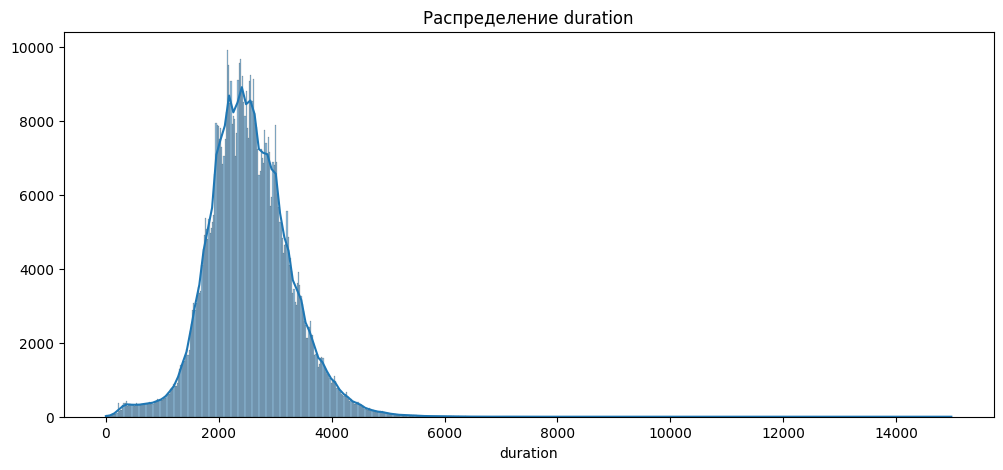

In [240]:
plt.figure(figsize=(12, 5))
sns.histplot(np.array(duration), kde=True)
plt.title('Распределение duration')
plt.xlabel('duration')
plt.ylabel('')

plt.show()

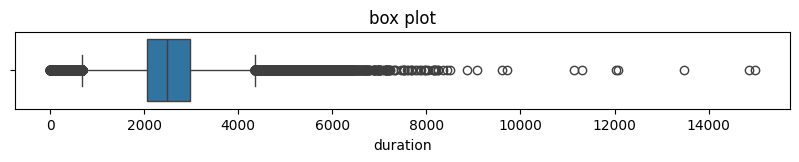

In [ ]:
plt.figure(figsize=(10, 1))
sns.boxplot(x=duration)
plt.title('box plot')
plt.show()

видно, что распределение скошено вправо, поэтому просто добавление константы в тестовую выборку даст смещение. используем заполнение простой лин регрессией. 

In [233]:
from sklearn.linear_model import LinearRegression

categorical = ["region", "game_mode"]


duration_preprocess = ColumnTransformer([
    ("ohe", OneHotEncoder(handle_unknown="ignore", sparse_output=False), categorical)
])

duration_model = Pipeline(steps=[
    ("preprocess", duration_preprocess),
    ("reg", LinearRegression())
])

duration_model.fit(train[categorical], train["duration"])

test["duration"] = duration_model.predict(test[categorical])

In [234]:
print(f"средняя duration в train: {train['duration'].mean():.0f}")
print(f"средняя duration в test: {test['duration'].mean():.0f}")

средняя duration в train: 2547
средняя duration в test: 2547


#### Задание 3.2. Простейшие преобразования (0.5 балла)

В жизни рядового датасаентиста часто возникает такая ситуация, что фича, которая ну должна быть клевой, на практике оказывается тем еще отстоем. Причин тому может быть несколько: признак действительно может быть нерелевантным, в данных банально может быть ошибка; либо же мы просто неправильно этот признак готовим. Народная мудрсть (и душнилы-математики) гласит, что признаки желательно подбирать из нормального распределения в случае L2-регуляризации, тогда как на практике это достигается ой как не всегда.

Сделаем следующее:

1. Посмотрите на гистограмму признака `duration`, если вы не сделали этого до. Что вы можете сказать про смещение, среднее, хвосты распределения этого признака?
2. Изучите три распространенных способа сделать признак $y$ ($y$ здесь и ниже это `duration`, не таргет) чуть более нормальным:

$$y \rightarrow \log y,  \sqrt{y}, \frac{1}{y}$$

Посмотрите, что происходит с распределением, если применить каждое из них.

3. Попробуйте добавить все три вышеперечисленных трансформации, вместе с признаком $\exp{\log{y}}$ (это снова `duration`).

Видно, что распределение сильно скошено вправо (длинный хвост из очень длинных матчей)

In [81]:
log_duration = np.log1p(duration)
sqrt_duration = np.sqrt(duration)
inv_duration = 1 / (duration + 1)
exp_log_duration = np.exp(np.log(duration + 1)) - 1

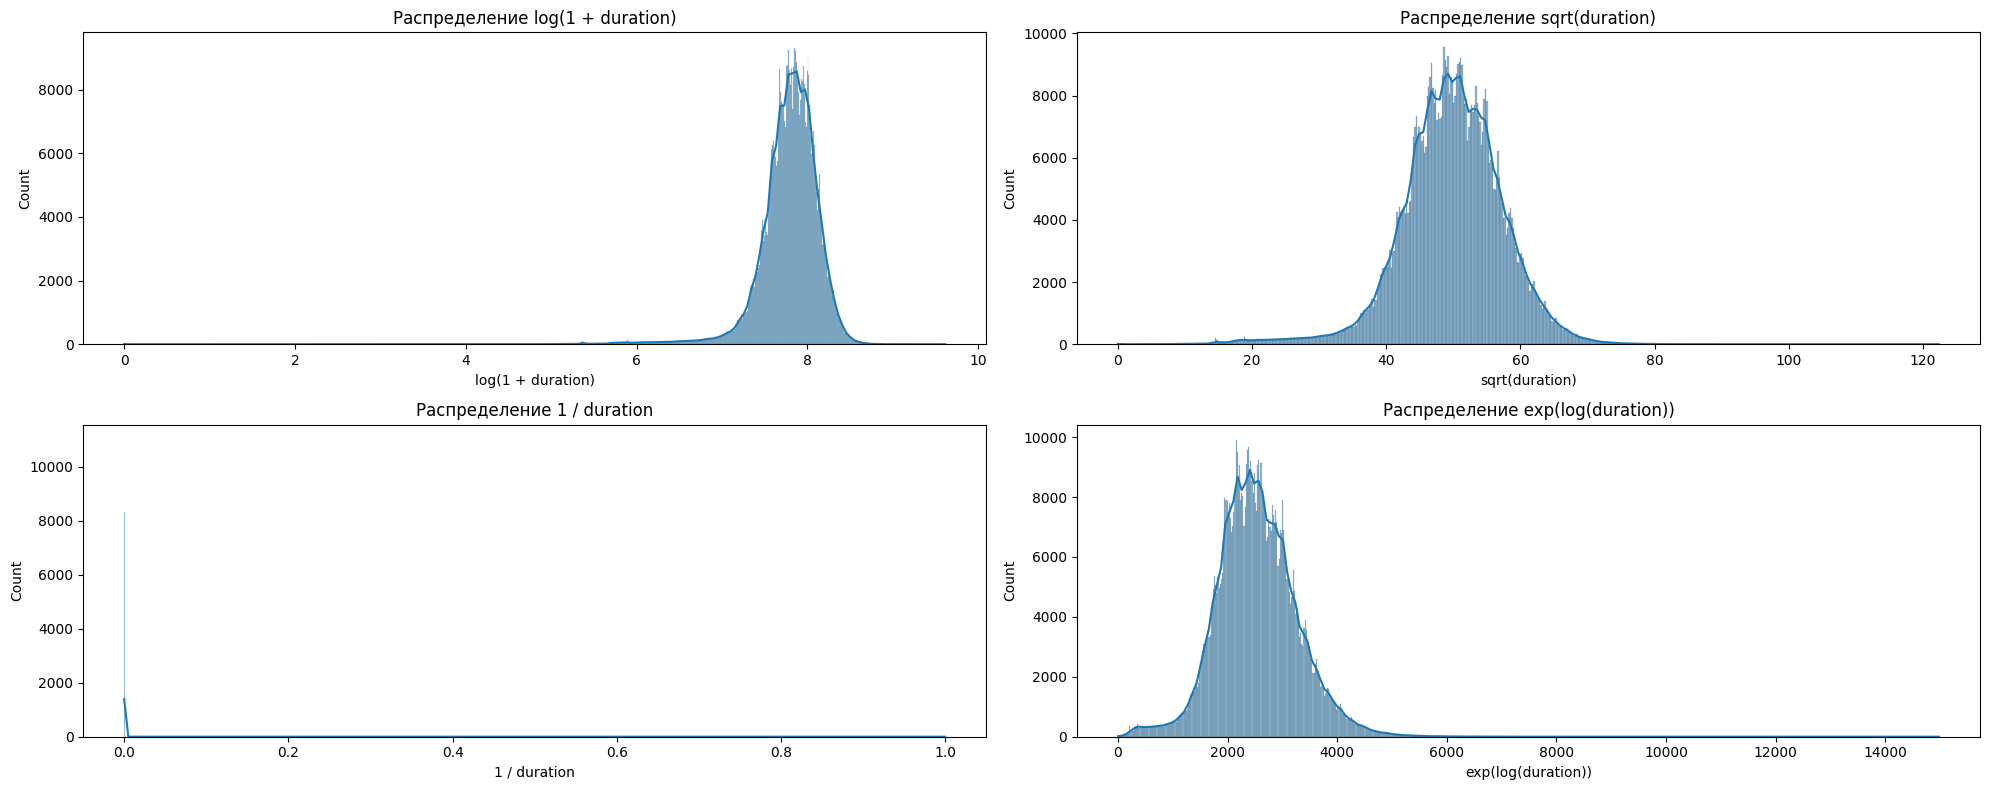

In [ ]:
plt.figure(figsize=(20, 8))

plt.subplot(2, 2, 1)
sns.histplot(np.array(log_duration), kde=True)
plt.title('Распределение log(1 + duration)')
plt.xlabel('log(1 + duration)')

plt.subplot(2, 2, 2)
sns.histplot(np.array(sqrt_duration), kde=True)
plt.title('Распределение sqrt(duration)')
plt.xlabel('sqrt(duration)')

plt.subplot(2, 2, 3)
sns.histplot(np.array(inv_duration), kde=True)
plt.title('Распределение 1 / duration')
plt.xlabel('1 / duration')

plt.subplot(2, 2, 4)
sns.histplot(np.array(exp_log_duration), kde=True)
plt.title('Распределение exp(log(duration))')
plt.xlabel('exp(log(duration))')


plt.tight_layout()
plt.show()

Трансформация 1/y не дает приближение к нормальному распределению, поэтому посмотрим на остальные две

In [186]:
train["log_duration"] = log_duration
train["sqrt_duration"] = sqrt_duration
train["inv_duration"] = inv_duration
train["exp_log_duration"] = exp_log_duration

categorical = ["region", "game_mode"]
numeric_features = [["exp_log_duration"], ["log_duration"], ["sqrt_duration"]]
target = train["radiant_win"]

def evaluate_model(numeric_features):
    X = train[categorical + numeric_features]
    y = target
    X_train, X_val, y_train, y_val = train_test_split(
        X, y, test_size=0.2, stratify=y, random_state=10
    )

    # Препроцессинг
    preprocessor = ColumnTransformer([
        ("ohe", OneHotEncoder(handle_unknown="ignore", sparse_output=False), categorical),
        ("scale", RobustScaler(), numeric_features)
    ])

    # Модель
    model = Pipeline([
        ("prep", preprocessor),
        ("clf", LogisticRegression(max_iter=1000, random_state=10))
    ])

    model.fit(X_train, y_train)
    y_pred_proba = model.predict_proba(X_val)[:, 1]
    return gini(y_val, y_pred_proba)

for f in numeric_features:
    print(f"для трансформации {f} gini = {evaluate_model(f)}")

для трансформации ['exp_log_duration'] gini = 0.07735789377958513
для трансформации ['log_duration'] gini = 0.07668303834308365
для трансформации ['sqrt_duration'] gini = 0.07739200472355501


In [187]:
train = train.drop(columns=["log_duration", "inv_duration", "exp_log_duration"])
train.head(5)

,match_id,date,region,game_mode,duration,radiant_win,sqrt_duration
0,1606558457,2024-01-01,3,1,50,True,7.071068
1,1533104773,2024-01-01,3,1,86,True,9.273618
2,1494396881,2024-01-01,3,1,211,True,14.525839
3,1457581060,2024-01-01,3,1,270,True,16.431677
4,1590242915,2024-01-01,3,21,318,True,17.832555


In [235]:
test["sqrt_duration"] = np.sqrt(test["duration"])
test.head(5)

,match_id,date,region,game_mode,duration,sqrt_duration
0,1509410699,2024-12-14,6,22,2544.777223,50.445785
1,1307322096,2024-12-15,12,22,2538.530024,50.383827
2,1427032882,2024-12-03,3,1,2603.879878,51.028226
3,1335981501,2024-12-29,3,1,2603.879878,51.028226
4,1305100719,2024-12-23,3,22,2561.973977,50.615946


#### Задание 3.3. Регионы (0.5 балла)

Не секрет, что в отдельных регионах уровень скилла игроков отличается в лучшую или худшую сторону. Даже простые, казалось бы, признаки, иногда оказываются полезными, если распределения таргета на них по какой-то причине отличаются друг от друга.

Ваша задача:

1. Построить распределение категорий признака `region` на графике.
2. Проверить, отличается ли распределение целевой переменной для разных категорий `region`.
3. Закодируйте признак (как именно - на ваше усмотрение, но вам может очень понравиться вот [эта](https://contrib.scikit-learn.org/category_encoders) библиотека).

In [37]:
train["region"].unique()

array([ 3,  4, 12,  9,  6, 11,  2, 10,  5,  1,  8,  7])

In [45]:
sns.set(style='darkgrid')

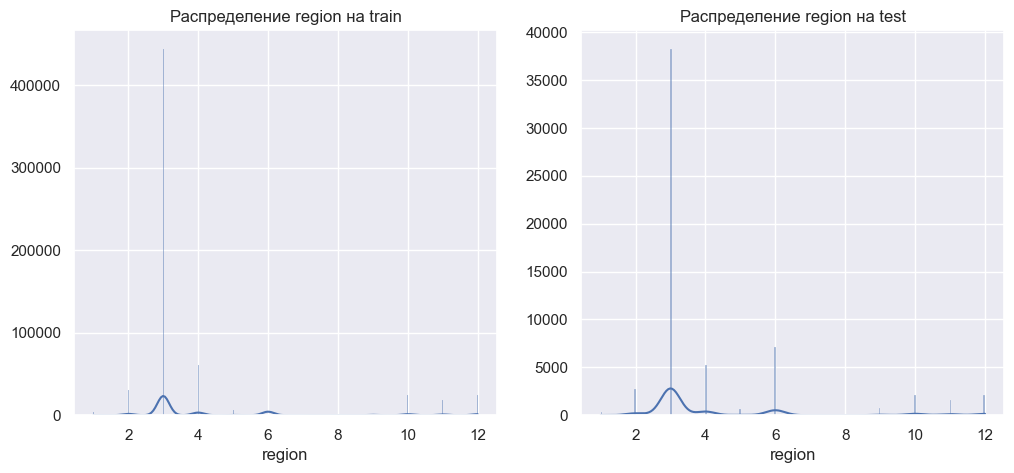

In [46]:
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
sns.histplot(np.array(train["region"]), kde=True)
plt.title('Распределение region на train')
plt.xlabel('region')
plt.ylabel('')

plt.subplot(1, 2, 2)
sns.histplot(np.array(test["region"]), kde=True)
plt.title('Распределение region на test')
plt.xlabel('region')
plt.ylabel('')

plt.show()

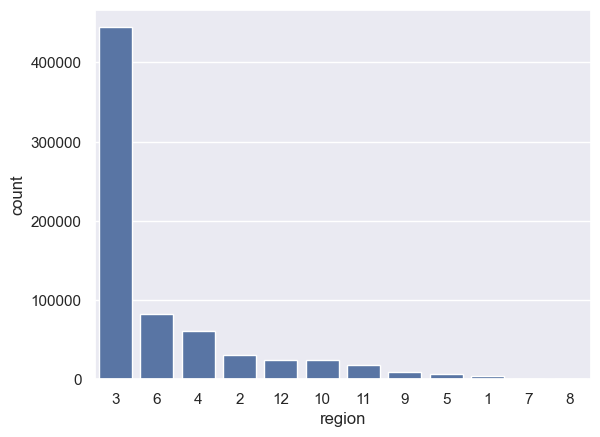

In [47]:
sns.countplot(data=train, x="region", order=train["region"].value_counts().index)
plt.show()

Количество матчей в 3 регион значительно превышает все остальные

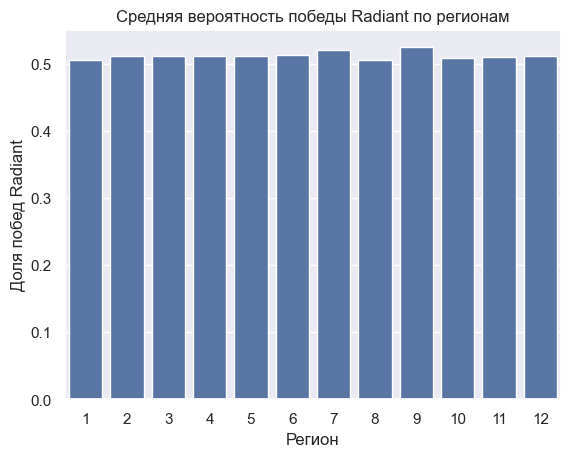

In [48]:
region_win_rate = (
    train.groupby("region")["radiant_win"].mean().sort_values(ascending=False))

sns.barplot(x=region_win_rate.index, y=region_win_rate.values)
plt.title("Средняя вероятность победы Radiant по регионам")
plt.xlabel("Регион")
plt.ylabel("Доля побед Radiant")
plt.show()

По графику признак region не кажется полезным, поскольку распределение таргета в различных регионах практически не отличается

In [88]:
import category_encoders as ce
encoder = ce.TargetEncoder(cols=["region"])

categorical = ["game_mode"]
numeric = ["sqrt_duration", "region"]

X = train[["region", "game_mode", "sqrt_duration"]]
y = train["radiant_win"]

X_train, X_val, y_train, y_val = train_test_split(X, y, stratify=y, test_size=0.2, random_state=10)

X_train_enc = encoder.fit_transform(X_train, y_train)
X_val_enc = encoder.transform(X_val)

X_train['region'] = X_train_enc['region']
X_val['region'] = X_val_enc['region']

# Препроцессинг
preprocessor = ColumnTransformer([
    ("ohe", OneHotEncoder(handle_unknown="ignore", sparse_output=False), categorical),
    ("scale", RobustScaler(), numeric)
])

# Модель
model = Pipeline([
    ("prep", preprocessor),
    ("clf", LogisticRegression(max_iter=1000, random_state=10))
])

model.fit(X_train_enc, y_train)
y_pred_proba = model.predict_proba(X_val_enc)[:, 1]
print(f"gini = {gini(y_val, y_pred_proba)}")

gini = 0.07744317113951027


In [89]:
X_train.head(10)

,region,game_mode,sqrt_duration
161213,0.513708,22,52.335456
98017,0.513708,1,51.303021
94681,0.512344,1,66.753277
396484,0.512344,3,48.579831
58747,0.511383,22,58.206529
660409,0.505234,1,54.258640
125937,0.512344,1,57.930993
394464,0.513708,22,49.355851
414504,0.512344,22,59.933296
129545,0.512344,4,51.788030


In [ ]:
test = encoder.transform(test[["region"]])

,match_id,date,region,game_mode,duration,sqrt_duration
0,1509410699,2024-12-14,6,22,2539.186231,50.390339
1,1307322096,2024-12-15,12,22,2532.846547,50.327394
2,1427032882,2024-12-03,3,1,2588.595615,50.878243
3,1335981501,2024-12-29,3,1,2588.595615,50.878243
4,1305100719,2024-12-23,3,22,2540.432863,50.402707
...,...,...,...,...,...,...
60949,1356667203,2024-12-08,3,1,2588.595615,50.878243
60950,1633554612,2024-12-12,3,1,2588.595615,50.878243
60951,1431018719,2024-12-03,3,22,2540.432863,50.402707
60952,1595824314,2024-12-10,6,4,2565.012284,50.645950


#### Задание 3.4. Даты (0.5 балла)

Бывалые игроки в доту знают, что игра постоянно (хотя это спорно) обновляется - в ней появляются новые механики, меняются старые и так далее. Разумно предположить, что со временем модель может вести себя чуточку по-другому. С временными изменениями часто помогает отслеживать изменение временных же признаков

Требуется:

1. Посмотреть, какие временные признаки можно достать, зная дату проведения матча
2. Подумать, есть ли какие-то знаменательные даты, которые могли повлиять на результаты матча (скажем, в одни дни игроки чуть более поддатые, или наоборот, в общем подумайте!)
2. Подумать, как именно вы хотите их кодировать (как числовые, категориальные, етц)
3. Вытащите хотя бы 2 разных временных признака из колонки `date`, добавьте хотя бы один флаг (признак со значением 1 или 0) для знаменательной даты

In [50]:
train_date = train.copy()

train_date['date'] = pd.to_datetime(train['date'])

train_date['year'] = train_date['date'].dt.year
train_date['month'] = train_date['date'].dt.month
train_date['day'] = train_date['date'].dt.day
train_date['weekday'] = train_date['date'].dt.weekday
train_date['hour'] = train_date['date'].dt.hour
train_date['is_weekend'] = train_date['weekday'].isin([5, 6]).astype(int)
train_date.head(7)

,match_id,date,region,game_mode,duration,radiant_win,sqrt_duration,year,month,day,weekday,hour,is_weekend
0,1606558457,2024-01-01,3,1,50,True,7.071068,2024,1,1,0,0,0
1,1533104773,2024-01-01,3,1,86,True,9.273618,2024,1,1,0,0,0
2,1494396881,2024-01-01,3,1,211,True,14.525839,2024,1,1,0,0,0
3,1457581060,2024-01-01,3,1,270,True,16.431677,2024,1,1,0,0,0
4,1590242915,2024-01-01,3,21,318,True,17.832555,2024,1,1,0,0,0
5,1605768990,2024-01-01,4,1,332,True,18.220867,2024,1,1,0,0,0
6,1541196419,2024-01-01,12,21,358,True,18.920888,2024,1,1,0,0,0


In [52]:
print(train_date['year'].unique())
train_date = train_date.drop(columns=["year"])

[2024]


In [57]:
print(train_date['hour'].unique())
train_date = train_date.drop(columns=["hour"])

[0]


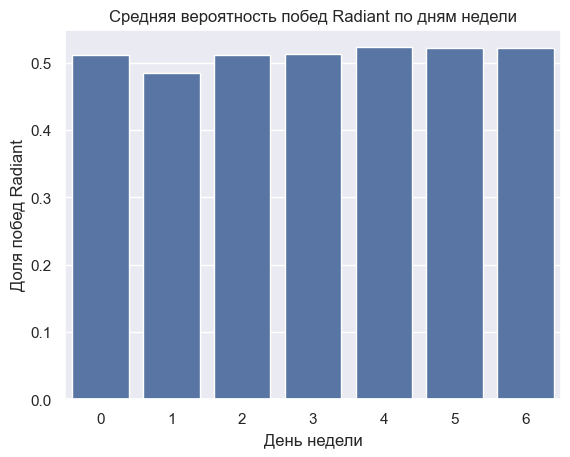

In [62]:
weekday_win_rate = (
    train_date.groupby("weekday")["radiant_win"].mean().sort_values(ascending=False))

sns.barplot(x=weekday_win_rate.index, y=weekday_win_rate.values)
plt.title('Средняя вероятность побед Radiant по дням недели')
plt.xlabel('День недели')
plt.ylabel('Доля побед Radiant')
plt.show()

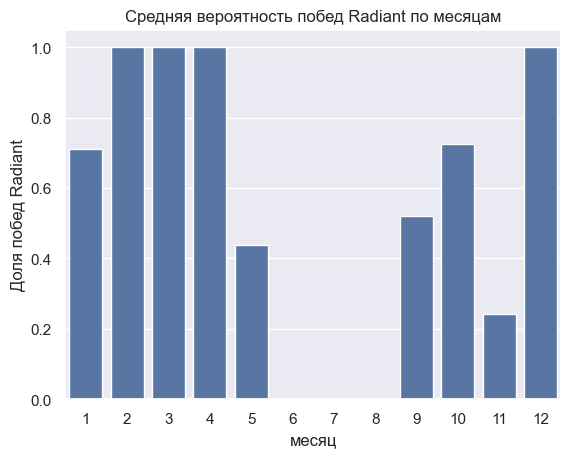

In [63]:
month_win_rate = (
    train_date.groupby("month")["radiant_win"].mean().sort_values(ascending=False))

sns.barplot(x=month_win_rate.index, y=month_win_rate.values)
plt.title('Средняя вероятность побед Radiant по месяцам')
plt.xlabel('месяц')
plt.ylabel('Доля побед Radiant')
plt.show()

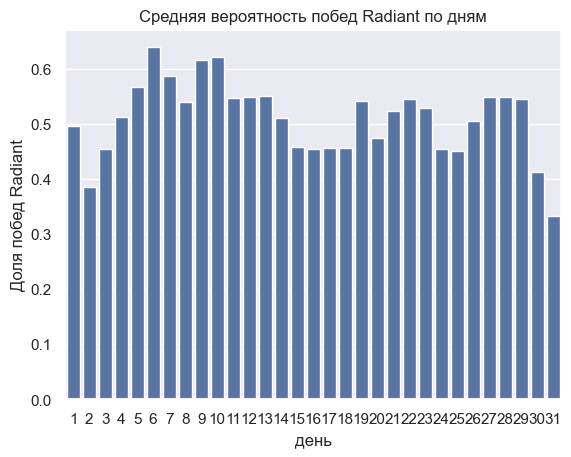

In [65]:
day_win_rate = (
    train_date.groupby("day")["radiant_win"].mean().sort_values(ascending=False))

sns.barplot(x=day_win_rate.index, y=day_win_rate.values)
plt.title('Средняя вероятность побед Radiant по дням')
plt.xlabel('день')
plt.ylabel('Доля побед Radiant')
plt.show()

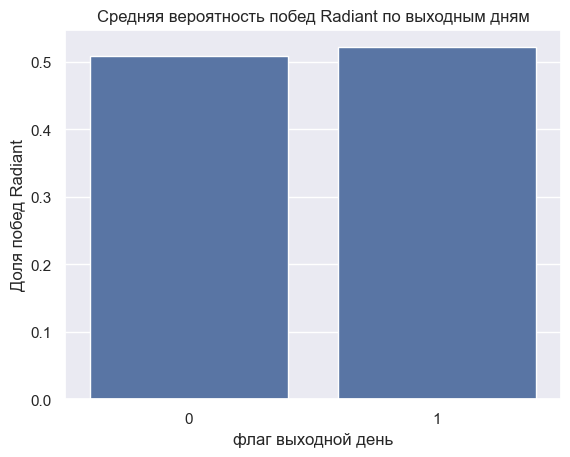

In [66]:
is_weekend_win_rate = (
    train_date.groupby("is_weekend")["radiant_win"].mean().sort_values(ascending=False))

sns.barplot(x=is_weekend_win_rate.index, y=is_weekend_win_rate.values)
plt.title('Средняя вероятность побед Radiant по выходным дням')
plt.xlabel('флаг выходной день')
plt.ylabel('Доля побед Radiant')
plt.show()

In [67]:
# знаменательные даты

train_date['is_new_year'] = ((train_date['date'].dt.month == 1) & (train_date['date'].dt.day <= 3)).astype(int)
train_date['is_ti_period'] = ((train_date['date'].dt.month >= 8) & (train_date['date'].dt.month <= 9)).astype(int) # international турниры

Кодирование

In [92]:
train_date['weekday_sin'] = np.sin(2 * np.pi * train_date['weekday'] / 7)
train_date['weekday_cos'] = np.cos(2 * np.pi * train_date['weekday'] / 7)

days_in_month = train_date['date'].dt.days_in_month
normalized_day = (train_date['day'] - 1) / (days_in_month - 1)
train_date['day_sin'] = np.sin(2 * np.pi * normalized_day)
train_date['day_cos'] = np.cos(2 * np.pi * normalized_day)

In [91]:
days_in_month = train_date['date'].dt.days_in_month
days_in_month.unique()

array([31, 29, 30], dtype=int32)

In [93]:
train_date.head(10)

,match_id,date,region,game_mode,duration,radiant_win,sqrt_duration,month,day,weekday,is_weekend,is_new_year,is_ti_period,weekday_sin,weekday_cos,day_sin,day_cos
0,1606558457,2024-01-01,3,1,50,True,7.071068,1,1,0,0,1,0,0.0,1.0,0.0,1.0
1,1533104773,2024-01-01,3,1,86,True,9.273618,1,1,0,0,1,0,0.0,1.0,0.0,1.0
2,1494396881,2024-01-01,3,1,211,True,14.525839,1,1,0,0,1,0,0.0,1.0,0.0,1.0
3,1457581060,2024-01-01,3,1,270,True,16.431677,1,1,0,0,1,0,0.0,1.0,0.0,1.0
4,1590242915,2024-01-01,3,21,318,True,17.832555,1,1,0,0,1,0,0.0,1.0,0.0,1.0
5,1605768990,2024-01-01,4,1,332,True,18.220867,1,1,0,0,1,0,0.0,1.0,0.0,1.0
6,1541196419,2024-01-01,12,21,358,True,18.920888,1,1,0,0,1,0,0.0,1.0,0.0,1.0
7,1486558998,2024-01-01,3,1,372,True,19.287302,1,1,0,0,1,0,0.0,1.0,0.0,1.0
8,1415399699,2024-01-01,3,3,379,True,19.467922,1,1,0,0,1,0,0.0,1.0,0.0,1.0
9,1518009122,2024-01-01,9,21,420,True,20.493902,1,1,0,0,1,0,0.0,1.0,0.0,1.0


In [189]:
train = train_date

In [175]:
train.head(5)

,match_id,date,region,game_mode,duration,radiant_win,sqrt_duration,month,day,weekday,is_weekend,is_new_year,is_ti_period,weekday_sin,weekday_cos,day_sin,day_cos
0,1606558457,2024-01-01,3,1,50,True,7.071068,1,1,0,0,1,0,0.0,1.0,0.0,1.0
1,1533104773,2024-01-01,3,1,86,True,9.273618,1,1,0,0,1,0,0.0,1.0,0.0,1.0
2,1494396881,2024-01-01,3,1,211,True,14.525839,1,1,0,0,1,0,0.0,1.0,0.0,1.0
3,1457581060,2024-01-01,3,1,270,True,16.431677,1,1,0,0,1,0,0.0,1.0,0.0,1.0
4,1590242915,2024-01-01,3,21,318,True,17.832555,1,1,0,0,1,0,0.0,1.0,0.0,1.0


In [236]:
test['date'] = pd.to_datetime(test['date'])

test['month'] = test['date'].dt.month
test['day'] = test['date'].dt.day
test['weekday'] = test['date'].dt.weekday
test['is_weekend'] = test['weekday'].isin([5, 6]).astype(int)
test['is_new_year'] = ((test['date'].dt.month == 1) & (test['date'].dt.day <= 3)).astype(int)
test['is_ti_period'] = ((test['date'].dt.month >= 8) & (test['date'].dt.month <= 9)).astype(int)

test['weekday_sin'] = np.sin(2 * np.pi * test['weekday'] / 7)
test['weekday_cos'] = np.cos(2 * np.pi * test['weekday'] / 7)

days_in_month = test['date'].dt.days_in_month
normalized_day = (test['day'] - 1) / (days_in_month - 1)
test['day_sin'] = np.sin(2 * np.pi * normalized_day)
test['day_cos'] = np.cos(2 * np.pi * normalized_day)

test = test.drop(columns=["day", "weekday"])
test

,match_id,date,region,game_mode,duration,sqrt_duration,month,is_weekend,is_new_year,is_ti_period,weekday_sin,weekday_cos,day_sin,day_cos
0,1509410699,2024-12-14,6,22,2544.777223,50.445785,12,1,0,0,-0.974928,-0.222521,0.406737,-0.913545
1,1307322096,2024-12-15,12,22,2538.530024,50.383827,12,1,0,0,-0.781831,0.623490,0.207912,-0.978148
2,1427032882,2024-12-03,3,1,2603.879878,51.028226,12,0,0,0,0.781831,0.623490,0.406737,0.913545
3,1335981501,2024-12-29,3,1,2603.879878,51.028226,12,1,0,0,-0.781831,0.623490,-0.406737,0.913545
4,1305100719,2024-12-23,3,22,2561.973977,50.615946,12,0,0,0,0.000000,1.000000,-0.994522,-0.104528
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
60949,1356667203,2024-12-08,3,1,2603.879878,51.028226,12,1,0,0,-0.781831,0.623490,0.994522,0.104528
60950,1633554612,2024-12-12,3,1,2603.879878,51.028226,12,0,0,0,0.433884,-0.900969,0.743145,-0.669131
60951,1431018719,2024-12-03,3,22,2561.973977,50.615946,12,0,0,0,0.781831,0.623490,0.406737,0.913545
60952,1595824314,2024-12-10,6,4,2554.928739,50.546303,12,0,0,0,0.781831,0.623490,0.951057,-0.309017


In [101]:
categorical = ["game_mode", "month"]
numeric = ["sqrt_duration", "region", "day_sin", "day_cos", "weekday_sin", "weekday_cos"]
other = ["is_weekend", "is_new_year", "is_ti_period"]

X = train[categorical + numeric + other]
y = train["radiant_win"]

X_train, X_val, y_train, y_val = train_test_split(X, y, stratify=y, test_size=0.2, random_state=10)

X_train_enc = encoder.fit_transform(X_train, y_train)
X_val_enc = encoder.transform(X_val)

X_train['region'] = X_train_enc['region']
X_val['region'] = X_val_enc['region']

# Препроцессинг
preprocessor = ColumnTransformer([
    ("ohe", OneHotEncoder(handle_unknown="ignore", sparse_output=False), categorical),
    ("scale", RobustScaler(), numeric)
])

# Модель
model = Pipeline([
    ("prep", preprocessor),
    ("clf", LogisticRegression(max_iter=1000, random_state=10))
])

model.fit(X_train, y_train)
y_pred_proba = model.predict_proba(X_val)[:, 1]
print(f"gini = {gini(y_val, y_pred_proba)}")

gini = 0.8849682083082455


#### Задание 3.5. Бинаризация (0.5 балла)

В нашем мире бывает так, что один отдельный признак оказывается настолько важен, или настолько сложен, что одним весом в линейной регрессии его ну никак не описать. Тогда на помощь часто приходит бинаризация. Ее суть заключается в том, что все распределение признака бьется на непересекающиеся бины и каждый из них уже можно закодировать, например, отдельной категорией бина. Попробуем?

Сделайте следующее:

1. Возьмите признак, который, как вам кажется, может быть хорошей целью для бинаризации. Это может быть что угодно до тех пор, пока признак вещественный.
2. Бинаризуйте признак произвольным способом (равномерная сетка, квантильная сетка, ...).
3. Проверьте, зашло там или нет.

/var/folders/yl/kh7ts60s19g89gh168b668t00000gn/T/ipykernel_15852/1617663829.py:9: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  quantile_stats = train.groupby('duration_quantile_bins').agg({


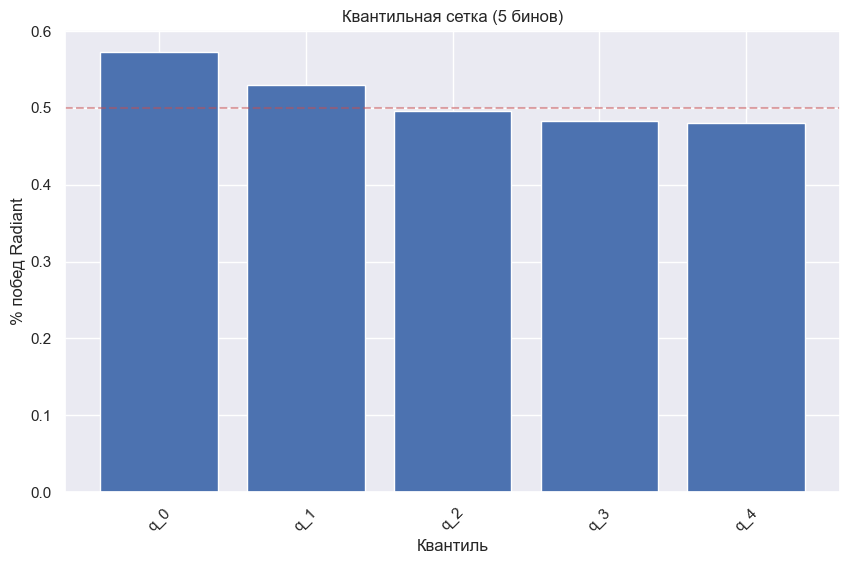

In [ ]:
n_bins_quantile = 5
train['duration_quantile_bins'] = pd.qcut(
    train['duration'], 
    q=n_bins_quantile, 
    labels=[f'q_{i}' for i in range(n_bins_quantile)],
    duplicates='drop'
)

quantile_stats = train.groupby('duration_quantile_bins').agg({
    'radiant_win': 'mean',
    'duration': 'count'
})

fig, ax = plt.subplots(1, 1, figsize=(10, 6))
ax.bar(range(len(quantile_stats)), quantile_stats['radiant_win'])
ax.set_title('Квантильная сетка (5 бинов)')
ax.set_xlabel('Квантиль')
ax.set_ylabel('% побед Radiant')
ax.set_xticks(range(len(quantile_stats)))
ax.set_xticklabels(quantile_stats.index, rotation=45)
ax.axhline(y=0.5, color='r', linestyle='--', alpha=0.5)
plt.show()

In [336]:
from sklearn.preprocessing import KBinsDiscretizer

binner = KBinsDiscretizer(n_bins=5, encode='ordinal', strategy='quantile')
train["duration_binned"] = binner.fit_transform(train[["duration"]]).astype(int)

categorical = ["game_mode", "month"]
numeric = ["duration_binned", "region", "day_sin", "day_cos", "weekday_sin", "weekday_cos"]
other = ["is_weekend", "is_new_year", "is_ti_period"]

X = train[categorical + numeric + other]
y = train["radiant_win"]

X_train, X_val, y_train, y_val = train_test_split(X, y, stratify=y, test_size=0.2, random_state=10)

X_train_enc = encoder.fit_transform(X_train, y_train)
X_val_enc = encoder.transform(X_val)

X_train['region'] = X_train_enc['region']
X_val['region'] = X_val_enc['region']

# Препроцессинг
preprocessor = ColumnTransformer([
    ("ohe", OneHotEncoder(handle_unknown="ignore", sparse_output=False), categorical),
    ("scale", RobustScaler(), numeric)
])

# Модель
model = Pipeline([
    ("prep", preprocessor),
    ("clf", LogisticRegression(max_iter=1000, random_state=10))
])

model.fit(X_train, y_train)
y_pred_proba = model.predict_proba(X_val)[:, 1]
print(f"gini = {gini(y_val, y_pred_proba)}")

gini = 0.885538873182899


чет не сработало

### **Задание 4. Эмбеддинги** (2 балла) <img align="center" src="https://static.wikia.nocookie.net/dota2_gamepedia/images/1/17/Emoticon_sick.gif/revision/latest?cb=20180504011850">

Пока что мы никак не использовали информацию про героев, а ведь от них напрямую зависит исход матча, их больше 100 штук и все они разные: кто-то сильнее, кто-то слабее. Делать мы это будем при помощи эмбеддингов. Это не самая универсальная техника, но зачастую она оказывается крайне полезной, ведь в векторном пространстве определено много веселых операций, например, поиск соседей, расстояние между векторами и прочее. Здесь мы познакомимся с самым простым способом их получения через прямое кодирование нужных категорий.

#### Задание 4.1. Эмбеддер героев (1 балл)

Посмотрите на табличку `player_df.csv`, в ней содержатся все герои, участвовавшие в матче. Ваша задача - закодировать каждый матч вектором, вида:

| match_id | match_embedding
| --- | --- |
| 228 | 1 0 0 -1 -1 0 0 |

Здесь `match_embedding` - закодированный вектор матча, каждый элемент которого принимает значение 1, если герой был в команде сил света, и -1, если в команде сил тьмы, подобно `OneHotEncoder`, но не совсем. Решение вставлять его одной колонкой или разбивать вектор на n колонок оставляем за вами.

Что хочется видеть:
1. Трансформер оформлен в виде отдельной функции или класса.
2. Трансформер принимает на вход аргумент `n_heroes`, который отвечает за то, подсчитываем мы наличие одного героя или может быть сразу нескольких, кажется ничего не мешает сразу масштабировать наше преобразование.
3. Трансформер корректно работает и корректно определяет, какой игрок из какой команды (обратите внимание на слотов игроков в матче и сообразите, как они соотносятся с командами).
4. Трансформер корректно применяется к трейну и валидации.

Детали реализации трансформера оставляем вам - можете воспользоваться [TransformerMixin](https://scikit-learn.org/stable/modules/generated/sklearn.base.TransformerMixin.html) и подогнать его под склерновский шаблон, можете воспользоваться готовыми трансформерами, а можете писать с нуля.

In [267]:
from itertools import combinations
from sklearn.base import BaseEstimator, TransformerMixin

class HeroesEmbedder(BaseEstimator, TransformerMixin):

    def __init__(self, n_heroes: int = 1):
        self.n_heroes = n_heroes
        self.hero_ids_ = None
        self.hero_combinations_ = None
        self.feature_names_ = None

    def fit(self, X, y=None):
        self.hero_ids_ = sorted(X['hero_id'].unique())

        if self.n_heroes == 1:
            self.hero_combinations_ = [(hero_id,) for hero_id in self.hero_ids_]
            self.feature_names_ = [f'hero_{hero_id}' for hero_id in self.hero_ids_]
        else:
            self.hero_combinations_ = list(combinations(self.hero_ids_, self.n_heroes))
            self.feature_names_ = [
                f'hero_{"_".join(map(str, combo))}' 
                for combo in self.hero_combinations_
            ]
        return self

    def transform(self, X, y=None):
        embeddings = []

        for match_id, group in X.groupby('match_id'):
            embedding = self._create_match_embedding(group)
            embeddings.append({'match_id': match_id, 'embedding': embedding})

        result_df = pd.DataFrame(embeddings)

        embedding_matrix = np.vstack(result_df['embedding'].values)
        embedding_df = pd.DataFrame(embedding_matrix, columns=self.feature_names_)
        result_df = pd.concat([
            result_df[['match_id']].reset_index(drop=True),
            embedding_df
        ], axis=1)
        
        return result_df
    
    def _create_match_embedding(self, match_group):

        radiant_heroes = set(match_group[match_group['player_slot'] < 128]['hero_id'].values)
        dire_heroes = set(match_group[match_group['player_slot'] >= 128]['hero_id'].values)

        embedding = np.zeros(len(self.hero_combinations_), dtype=int)

        for idx, combo in enumerate(self.hero_combinations_):
            if self.n_heroes == 1:
                hero_id = combo[0]
                if hero_id in radiant_heroes:
                    embedding[idx] = 1
                elif hero_id in dire_heroes:
                    embedding[idx] = -1
            else:
                n_in_radiant = sum(1 for h in combo if h in radiant_heroes)
                n_in_dire = sum(1 for h in combo if h in dire_heroes)
                
                if n_in_radiant == self.n_heroes:
                    embedding[idx] = self.n_heroes
                elif n_in_dire == self.n_heroes:
                    embedding[idx] = -self.n_heroes
                else:
                    embedding[idx] = n_in_radiant - n_in_dire
        
        return embedding


Как проверить корректность эмбеддера:

1) Для каждого матча горизонтальная сумма должна быть 0, то есть ровно 5 героев сил Света и 5 героев сил Тьмы. Если у вас получилось не так - не спешите ставить крест на карьере дата сайентиста, а посмотрите на эти матчи подробнее, выведите их, проанализируйте и решите, что с этим делать.
2) Для каждого матча значений '1' и '-1' должно быть ровно 5, все игроки должны иметь уникальный `id`. Опять же, если это не так - покажите, где это происходит и решите, что с этим делать.

In [269]:
embedder = HeroesEmbedder(n_heroes=1)
embeds = embedder.fit_transform(players_df)

In [272]:
players_df["hero_id"].nunique()

111

In [280]:
players_df['match_id'].nunique()

767821

In [284]:
print(f"\nСоздано {len(embeds)} эмбеддингов матчей")
print(f"Размерность каждого вектора: {len(embedder.feature_names_)}")
print(f"\nПример эмбеддинга первого матча:")
sample_match = embeds.head(1)
sample_match


Создано 767821 эмбеддингов матчей
Размерность каждого вектора: 111

Пример эмбеддинга первого матча:


,match_id,hero_0,hero_1,hero_2,hero_3,hero_4,hero_5,hero_6,hero_7,hero_8,...,hero_102,hero_103,hero_104,hero_105,hero_106,hero_107,hero_109,hero_110,hero_111,hero_112
0,245413525,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


In [290]:
sample_match_id = sample_match["match_id"][0]
match_data = players_df[players_df['match_id'] == sample_match_id]
radiant_heroes = set(match_data[match_data['player_slot'] < 128]['hero_id'].values)
dire_heroes = set(match_data[match_data['player_slot'] >= 128]['hero_id'].values)
radiant_heroes

{np.int64(15), np.int64(49), np.int64(62), np.int64(66), np.int64(91)}

In [292]:
match_embedding = sample_match.squeeze()
radiant_heroes_cols = match_embedding[match_embedding == 1].index.tolist()
radiant_heroes_cols

['hero_15', 'hero_49', 'hero_62', 'hero_66', 'hero_91']

вроде все работает

In [294]:
embedding_matrix = embeds.iloc[:, 1:].values
sums = embedding_matrix.sum(axis=1)

correct_sum = (sums == 0).sum()
incorrect_sum = (sums != 0).sum()

print(f"\nПроверка суммы (должна быть 0):")
print(f"Корректных матчей: {correct_sum}")
print(f"Некорректных матчей: {incorrect_sum}")


Проверка суммы (должна быть 0):
Корректных матчей: 766710
Некорректных матчей: 1111


In [295]:
incorrect_match_ids = embeds[sums != 0]['match_id'].to_list()

incorrect_in_train = [m for m in incorrect_match_ids if m in train_match_ids]
incorrect_in_test = [m for m in incorrect_match_ids if m in test_match_ids]

print(f"Некорректных матчей в train: {len(incorrect_in_train)}")
print(f"Некорректных матчей в test: {len(incorrect_in_test)}")

Некорректных матчей в train: 1018
Некорректных матчей в test: 87


In [296]:
train = train[~train['match_id'].isin(incorrect_in_train)].copy()

In [338]:
duplicates = []
for match_id, group in players_df.groupby('match_id'):
    hero_counts = group['hero_id'].value_counts()
    if (hero_counts > 1).any():
        duplicates.append(match_id)
len(duplicates)

1053

In [297]:
embeds_train = embeds[embeds['match_id'].isin(train['match_id'])].copy()
embeds_test = embeds[embeds['match_id'].isin(test['match_id'])].copy()

In [309]:
print(train.shape)
print(embeds_train.shape)
print(test.shape)
print(embeds_test.shape)

(705836, 45)
(705833, 112)
(60953, 4)
(60952, 112)


In [310]:
print(train["match_id"].nunique() + test["match_id"].nunique())

766786


In [311]:
players_df["match_id"].nunique()

767821

Если вы уверены в своей правоте - присоедините эти данные к обучающей и валидационной выборке, и обучите модель.

In [312]:
train = train.merge(embeds_train, on='match_id', how='left')
test = test.merge(embeds_test, on='match_id', how='left')

In [ ]:
for df,name in [(train,"train"), (test,"test")]:
    s = df.isna().sum()
    s = s[s>0].sort_values(ascending=False)
    print(f"\nПропуски в {name}:\n", s)


Пропуски в train:
 Series([], dtype: int64)

Пропуски в test:
 Series([], dtype: int64)


In [ ]:
test.columns

Index(['match_id', 'date', 'region', 'game_mode', 'hero_0', 'hero_1', 'hero_2',
       'hero_3', 'hero_4', 'hero_5',
       ...
       'hero_102', 'hero_103', 'hero_104', 'hero_105', 'hero_106', 'hero_107',
       'hero_109', 'hero_110', 'hero_111', 'hero_112'],
      dtype='object', length=115)


In [322]:
categorical = ["game_mode", "month"]
numeric = ["sqrt_duration", "region", "day_sin", "day_cos", "weekday_sin", "weekday_cos"]
other = ["is_weekend", "is_new_year", "is_ti_period"]

hero_cols = [col for col in train.columns if col.startswith('hero_')]
numeric = numeric + hero_cols

X = train[categorical + numeric + other]
y = train["radiant_win"]

X_train, X_val, y_train, y_val = train_test_split(X, y, stratify=y, test_size=0.2, random_state=10)

X_train_enc = encoder.fit_transform(X_train, y_train)
X_val_enc = encoder.transform(X_val)

X_train['region'] = X_train_enc['region']
X_val['region'] = X_val_enc['region']

# Препроцессинг
preprocessor = ColumnTransformer([
    ("ohe", OneHotEncoder(handle_unknown="ignore", sparse_output=False), categorical),
    ("scale", RobustScaler(), numeric)
])

# Модель
model = Pipeline([
    ("prep", preprocessor),
    ("clf", LogisticRegression(max_iter=1000, random_state=10))
])

model.fit(X_train, y_train)
y_pred_proba = model.predict_proba(X_val)[:, 1]
print(f"gini = {gini(y_val, y_pred_proba)}")

gini = 0.8980859534474681


#### Задание 4.2. Эмбеддер винрейта (1 балл)

Помимо данных о присутствии героев, явно не помешает статистика, как часто эти герои выигрывают. Логично предположить, что если герой, например всеми любимый Pudge, побеждает в 99% игр, шансы на победу в будущих матчах тоже крайне высоки.

**Вопрос:** Как вы считаете, полезен ли будет этот признак, если мы уже сделали эмбеддинг героев из предыдущего пункта?

**Ответ:**
да, несмотря на то, что мы знаем, какие герои в матче, мы не знаем, насколько они сильные

Еще одна народная мудрость, которая часто встречается в мире машинного обучения: чем лучше получается декомпозировать тот или иной признак, тем лучше. Фактически шанс на победу определенного героя, или пары-тройки-четверки героев, определяется не только тем, как часто они побеждают, но их как часто их берут, подумайте почему (необязательно вслух).

Давайте сделаем такой трансформер:

| match_id | wincount_embedding | pickcount_embedding |
| --- | --- | --- |
| 228 | 1 0 0 0 1 0 0 | 1 0 0 0 1 0 0 |
| 322 | 0.5 0 0 0 1 0 0 | 2 0 0 0 2 0 0 |
| 1337| 0.33 0 0 1 0.5 0 0 | 3 0 0 1 3 0 0 |
| ... | ... | ... |

1. Трансформер оформлен в виде класса или функции.
2. Трансформер подсчитывает **кумулятивное** число побед (`wincount_HERO`) и кумулятивное число матчей (`pickcount_HERO`) для каждого героя на тренировочной выборке и средний винрейт, средний пикрейт по герою на валидационной выборке (средние будем собирать в методе `fit`).
3. Если героя в матче нет, его винрейт не интересен, поэтому элементы эмбеддинга там будут 0.
4. Трансформер все еще может работать для связок героев, поэтому параметр `n_heroes` оставялем нетронутым.

In [345]:
players_df = players_df.merge(train[["match_id", "radiant_win"]], on="match_id", how="left")

In [341]:
import pandas as pd
import numpy as np
from sklearn.base import BaseEstimator, TransformerMixin

class WinrateEmbedder(BaseEstimator, TransformerMixin):
    def __init__(self, n_heroes: int = 1, aggregate: bool = False):
        self.n_heroes = n_heroes
        self.aggregate = aggregate  # если True — делаем winrate_embedding
        self.hero_ids_ = None
        self.pickcounts_ = None
        self.wincounts_ = None

    def fit(self, X, y=None):
        self.hero_ids_ = sorted(X["hero_id"].unique())
        self.pickcounts_ = {hid: 0 for hid in self.hero_ids_}
        self.wincounts_ = {hid: 0 for hid in self.hero_ids_}

        for _, row in X.iterrows():
            hid = row["hero_id"]
            self.pickcounts_[hid] += 1
            if row["radiant_win"] == (row["player_slot"] < 128):
                self.wincounts_[hid] += 1
        return self

    def transform(self, X, y=None):
        n_heroes = len(self.hero_ids_)
        match_rows = []

        for match_id, group in X.groupby("match_id"):
            win_vec = np.zeros(n_heroes)
            pick_vec = np.zeros(n_heroes)
            for _, row in group.iterrows():
                hid = row["hero_id"]
                hero_index = self.hero_ids_.index(hid)
                pick_vec[hero_index] += 1
                if row["radiant_win"] == (row["player_slot"] < 128):
                    win_vec[hero_index] += 1

            if self.aggregate:
                with np.errstate(divide='ignore', invalid='ignore'):
                    winrate_vec = np.nan_to_num(win_vec / pick_vec)
                match_rows.append((match_id, " ".join(map(str, winrate_vec))))
            else:
                match_rows.append((match_id,
                                   " ".join(map(str, win_vec)),
                                   " ".join(map(str, pick_vec))))

        if self.aggregate:
            return pd.DataFrame(match_rows, columns=["match_id", "winrate_embedding"])
        return pd.DataFrame(match_rows, columns=["match_id", "wincount_embedding", "pickcount_embedding"])


Как проверить корректность эмбеддера:

1) `pickcount` и `wincount` для каждого героя должны быть неубывающими, если ваш датафрейм отсортирован по дате.
2) Для каждого матча ненулевых значений в обоих эмбеддингах должно быть не более 10.

In [346]:
wr_embedder = WinrateEmbedder(aggregate=True)
wr_embeds = wr_embedder.fit_transform(players_df)
print(wr_embeds.head())

    match_id                                  winrate_embedding
0  245413525  0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 1....
1  271145478  0.0 0.0 0.0 0.0 0.0 1.0 0.0 0.0 0.0 0.0 0.0 0....
2  610497965  0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0....
3  613258812  0.0 0.0 0.0 1.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 1....
4  639442405  0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 1....


In [349]:
train = train.merge(wr_embeds, on="match_id", how="left")
winrate_vectors = train['winrate_embedding'].apply(lambda x: np.fromstring(x, sep=' '))
winrate_matrix = np.vstack(winrate_vectors)

winrate_cols = [f"winrate_{i+1}" for i in range(winrate_matrix.shape[1])]
train[winrate_cols] = winrate_matrix

/var/folders/yl/kh7ts60s19g89gh168b668t00000gn/T/ipykernel_15852/1552177756.py:6: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  train[winrate_cols] = winrate_matrix
/var/folders/yl/kh7ts60s19g89gh168b668t00000gn/T/ipykernel_15852/1552177756.py:6: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  train[winrate_cols] = winrate_matrix
/var/folders/yl/kh7ts60s19g89gh168b668t00000gn/T/ipykernel_15852/1552177756.py:6: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, whic

In [350]:
winrate_matrix

array([[0., 0., 0., ..., 1., 0., 0.],
       [0., 0., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 0.],
       ...,
       [0., 0., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 1.],
       [0., 0., 0., ..., 1., 0., 0.]])

Если вы считаете, что у вас все отлично, то вам также предлагается подумать - хотим ли мы делать вектор `winrate_embedding` вместо двух отдельных? Каково бы ни было ваше решение, обучите модель и замерьте качество.

In [351]:
categorical = ["game_mode", "month"]
numeric = ["sqrt_duration", "region", "day_sin", "day_cos", "weekday_sin", "weekday_cos"]
other = ["is_weekend", "is_new_year", "is_ti_period"]

hero_cols = [col for col in train.columns if col.startswith('hero_')]
numeric = ["sqrt_duration", "region", "day_sin", "day_cos", "weekday_sin", "weekday_cos"] + hero_cols + winrate_cols

X = train[categorical + numeric + other]
y = train["radiant_win"]

X_train, X_val, y_train, y_val = train_test_split(X, y, stratify=y, test_size=0.2, random_state=10)

X_train_enc = encoder.fit_transform(X_train, y_train)
X_val_enc = encoder.transform(X_val)

X_train['region'] = X_train_enc['region']
X_val['region'] = X_val_enc['region']

# Препроцессинг
preprocessor = ColumnTransformer([
    ("ohe", OneHotEncoder(handle_unknown="ignore", sparse_output=False), categorical),
    ("scale", RobustScaler(), numeric)
])

# Модель
model = Pipeline([
    ("prep", preprocessor),
    ("clf", LogisticRegression(max_iter=1000, random_state=10))
])

model.fit(X_train, y_train)
y_pred_proba = model.predict_proba(X_val)[:, 1]
print(f"gini = {gini(y_val, y_pred_proba)}")

gini = 0.8981915777967275


### **Задание 5. Агрегации** (2 балла) <img align="center" src="https://static.wikia.nocookie.net/dota2_gamepedia/images/4/4a/Techies_emoticon.gif/revision/latest?cb=20180504014918">

Одна из самых эффективных и в то же время громоздких трансформаций, которые можно сделать с данными - это разного рода агрегации. В первом дз мы немножко баловались с `group_by`, теперь сделаем то же самое, но уже на стероидах. Идея здесь максимально проста - схлопнуть массив данных до одного или нескольких чисел, которые эти данные описывают. Как правило, это довольно эффективная техника, но крайне громоздкая, например, для $n$ признаков, $m$ агрегаций и $d$ размера окна агрегаций, признаков получится чуть ли не $n \cdot m \cdot d$, что немало.

#### Задание 5.1. Статистики матча (0.5 балла)

Из данных, что мы все еще не использовали, есть статистики матча. На протяжении игры каждая команда зарабатывает золото и опыт. Как правило, считается, что чем циферки больше, тем больше у команды шансов на выигрыш. Разумеется, это не гарантия, но это мы сейчас и проверим. Ниже вы можете увидеть пример графика преимущества, на который мы и будем смотреть.

<img src="https://media.discordapp.net/attachments/674191702906503199/1429333425436885003/52733B32-B6C2-49FF-AABB-C3A4B3035F16.png?ex=68f5c1fc&is=68f4707c&hm=a01032723e1f1653b34f47e340ac7751d07f485b4592d0f968fc046f148a9b53&=&format=webp&quality=lossless&width=771&height=544">

Положительное значение - преимущество в пользу команды Radiant, негативное - в пользу команды Dire. Каждое значение колонки `..._adv` содержит в себе массив значений, каждый из которых представляет из себя график, или распределение, у которого есть какие-то параметры, надо бы их достать.

Сделаем вот что:
1. Посмотрите на колонки с суффиксом `_adv`.
2. Проверьте их на наличие нанов и всяких смешных краевых случаев. В первую очередь нас интересует, чтобы они не были пустыми и чтобы в них было ровно 16 значений.
3. Посчитайте простые статистики распределения, хотя бы штуки 4. Часть из них вы можете знать из курса статистики, часть вы можете найти в вашей любимой библиотеке для обработки данных, например [тут](https://docs.pola.rs/api/python/stable/reference/expressions/computation.html) или [тут](https://docs.pola.rs/api/python/stable/reference/expressions/aggregation.html), какие-то признаки вы можете достать, если вспомните матан и подумаете, как фанфакты про график могут помочь модели. Для референса можете поиграть в "что хотел сказать автор" на графике выше, там есть несколько подсказок.
4. Проанализируйте, насколько это может оказаться полезным, - постройте heatmap корреляции посчитанных вами признаков с целевой переменной и между собой и сделайте вывод.

In [ ]:
match_stats_look = match_stats.copy()

def parse(object):
    off_brackets = object.strip('[]')

    if not off_brackets:
        return []
    
    return list(map(int, off_brackets.split()))

match_stats_look['gold_adv_list'] = match_stats_look['radiant_gold_adv'].apply(parse)
match_stats_look['exp_adv_list'] = match_stats_look['radiant_exp_adv'].apply(parse)

In [ ]:
match_stats_look['gold_len'] = match_stats_look['gold_adv_list'].apply(len)
match_stats_look['exp_len'] = match_stats_look['exp_adv_list'].apply(len)

print("\nРаспределение длины gold_adv_list:")
print(match_stats_look['gold_len'].value_counts().sort_index())

print("\nРаспределение длины exp_adv_list:")
print(match_stats_look['exp_len'].value_counts().sort_index())


Распределение длины gold_adv_list:
gold_len
0     529783
16    238039
Name: count, dtype: int64

Распределение длины exp_adv_list:
exp_len
0     529783
16    238039
Name: count, dtype: int64


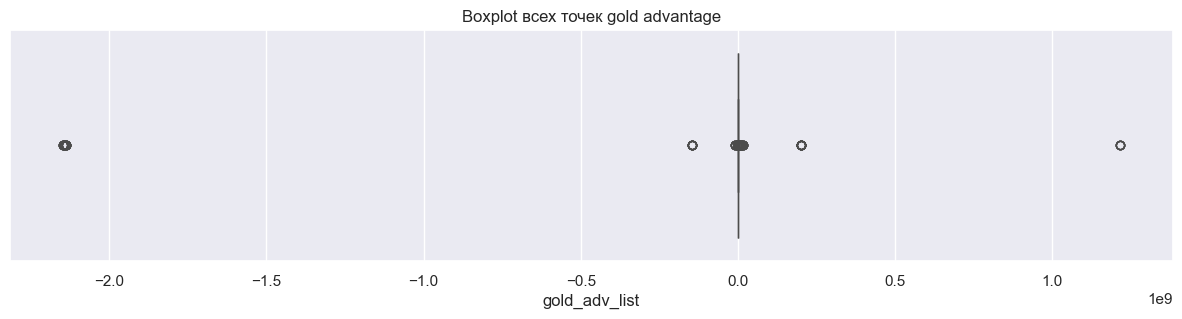

In [152]:
all_gold_adv_values = match_stats_look['gold_adv_list'].explode().dropna()
all_gold_adv_values = pd.to_numeric(all_gold_adv_values, errors='coerce').dropna()

all_exp_adv_values = match_stats_look['exp_adv_list'].explode().dropna()
all_exp_adv_values = pd.to_numeric(all_exp_adv_values, errors='coerce').dropna()

plt.figure(figsize=(15, 3))
sns.boxplot(x=all_gold_adv_values)
plt.title('Boxplot всех точек gold advantage')
plt.show()

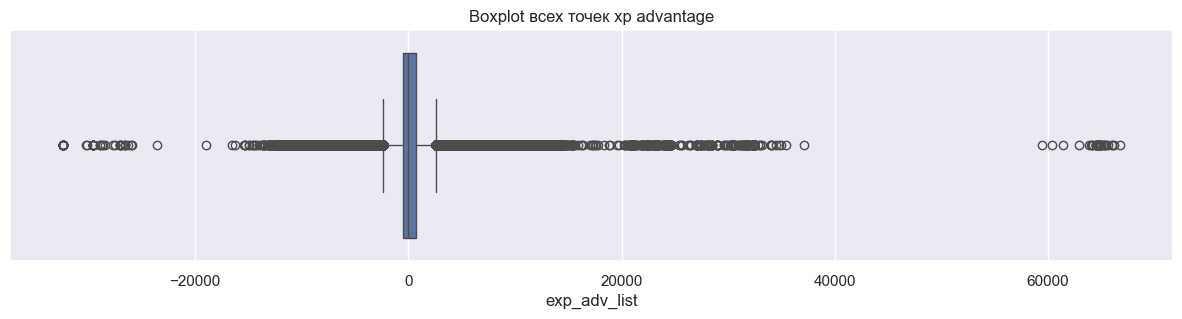

In [154]:
plt.figure(figsize=(15, 3))
sns.boxplot(x=all_exp_adv_values)
plt.title('Boxplot всех точек xp advantage')
plt.show()

In [ ]:
import numpy as np

def contains_extreme_error(series_list, threshold=1000000):
    if not series_list:
        return False
    
    return np.max(np.abs(np.array(series_list))) > threshold

match_stats_look['is_gold_adv_error'] = match_stats_look['gold_adv_list'].apply(contains_extreme_error)

error_count = match_stats_look['is_gold_adv_error'].sum()

print(f"Найдено {error_count} матчей с экстремальной ошибкой в gold_adv.")

Найдено 19 матчей с экстремальной ошибкой в gold_adv.


In [156]:
error_rows = match_stats_look[match_stats_look['is_gold_adv_error']]
error_rows

,match_id,radiant_gold_adv,radiant_exp_adv,gold_adv_list,exp_adv_list,gold_len,exp_len,is_gold_adv_error
20637,1569068099,[-2144939851 -2144935893 -2144929617 -21449275...,[65002 65108 66013 65974 66192 66705 24425 244...,"[-2144939851, -2144935893, -2144929617, -21449...","[65002, 65108, 66013, 65974, 66192, 66705, 244...",16,16,True
52797,1590174171,[ 999999 1000099 1000199 1000299 1000399 10015...,[32400 32400 32400 32400 32400 32400 32400 231...,"[999999, 1000099, 1000199, 1000299, 1000399, 1...","[32400, 32400, 32400, 32400, 32400, 32400, 324...",16,16,True
143360,1598900299,[2146728 2147593 2147855 2147955 2148978 21498...,[32400 32400 32400 32400 32400 32400 32292 320...,"[2146728, 2147593, 2147855, 2147955, 2148978, ...","[32400, 32400, 32400, 32400, 32400, 32400, 322...",16,16,True
278012,1561908557,[-2137483650 -2137483550 -2137483296 -21374831...,[32400 32400 32400 32400 32400 32400 32400 324...,"[-2137483650, -2137483550, -2137483296, -21374...","[32400, 32400, 32400, 32400, 32400, 32400, 324...",16,16,True
280402,1572152475,[1127499 1131033 1131641 1133032 1101677 10938...,[65288 65200 64532 64123 37075 30258 22370 221...,"[1127499, 1131033, 1131641, 1133032, 1101677, ...","[65288, 65200, 64532, 64123, 37075, 30258, 223...",16,16,True
319088,1537886733,[ 0 1214123728 1214123514 1214124763 1...,[ 0 64240 62902 61417 60404 59428 30398 303...,"[0, 1214123728, 1214123514, 1214124763, 121412...","[0, 64240, 62902, 61417, 60404, 59428, 30398, ...",16,16,True
338687,1588890228,[200000458 200002077 200004013 199998440 19999...,[32400 32010 31340 24471 22543 21873 21873 218...,"[200000458, 200002077, 200004013, 199998440, 1...","[32400, 32010, 31340, 24471, 22543, 21873, 218...",16,16,True
345277,1589467513,[-147483651 -147483732 -147484231 -147532195 -...,[32400 64910 64836 63976 63866 64657 31760 315...,"[-147483651, -147483732, -147484231, -14753219...","[32400, 64910, 64836, 63976, 63866, 64657, 317...",16,16,True
359338,1593933331,[10114766 10114272 10114103 10114625 10115701 ...,[64800 64800 64800 64800 64800 64800 30434 304...,"[10114766, 10114272, 10114103, 10114625, 10115...","[64800, 64800, 64800, 64800, 64800, 64800, 304...",16,16,True
363017,1582570829,[2141709 2142009 2143653 2143753 2145044 21466...,[32400 32400 32400 32400 32400 32400 22428 224...,"[2141709, 2142009, 2143653, 2143753, 2145044, ...","[32400, 32400, 32400, 32400, 32400, 32400, 224...",16,16,True


In [157]:
match_stats = match_stats_look[~match_stats_look['is_gold_adv_error']]
match_stats

,match_id,radiant_gold_adv,radiant_exp_adv,gold_adv_list,exp_adv_list,gold_len,exp_len,is_gold_adv_error
0,1340959379,[],[],NaN,NaN,16,16,False
1,1377521758,[],[],NaN,NaN,16,16,False
2,1457973639,[],[],NaN,NaN,16,16,False
3,1629821522,[],[],NaN,NaN,16,16,False
4,1529300845,[ 0 334 179 655 31 1029 1029 1029 662 ...,[ 0 147 105 -9 -651 -471 -471 -7...,"[0, 334, 179, 655, 31, 1029, 1029, 1029, 662, ...","[0, 147, 105, -9, -651, -471, -471, -723, -441...",16,16,False
...,...,...,...,...,...,...,...,...
767829,1601209593,[],[],NaN,NaN,16,16,False
767830,1387531049,[],[],NaN,NaN,16,16,False
767831,1615293881,[],[],NaN,NaN,16,16,False
767832,1423370565,[],[],NaN,NaN,16,16,False


In [110]:
train_match_ids = set(train['match_id'])
test_match_ids = set(test['match_id'])

matches_with_missing = match_stats[(match_stats['gold_adv_list'].isna()) | (match_stats['exp_adv_list'].isna())]["match_id"]
missing_in_train = [m for m in matches_with_missing if m in train_match_ids]
missing_in_test = [m for m in matches_with_missing if m in test_match_ids]

print(len(missing_in_train))
print(len(missing_in_test))

487871
41913


In [158]:
def parse(object):
    if pd.isna(object):
        return [0] * 16
    off_brackets = object.strip('[]').strip()
    if not off_brackets:
        return [0] * 16
    return list(map(int, off_brackets.split()))

match_stats['gold_adv_list'] = match_stats['radiant_gold_adv'].apply(parse)
match_stats['exp_adv_list'] = match_stats['radiant_exp_adv'].apply(parse)

/var/folders/yl/kh7ts60s19g89gh168b668t00000gn/T/ipykernel_15852/2850203897.py:9: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  match_stats['gold_adv_list'] = match_stats['radiant_gold_adv'].apply(parse)
/var/folders/yl/kh7ts60s19g89gh168b668t00000gn/T/ipykernel_15852/2850203897.py:10: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  match_stats['exp_adv_list'] = match_stats['radiant_exp_adv'].apply(parse)


In [159]:
def extract_from_match_stats(list_series):
    return pd.DataFrame({
        "mean": list_series.apply(lambda x: np.mean(x) if len(x) > 0 else np.nan),
        "max":  list_series.apply(lambda x: np.max(x) if len(x) > 0 else np.nan),
        "min":  list_series.apply(lambda x: np.min(x) if len(x) > 0 else np.nan),
        "last": list_series.apply(lambda x: x[-1] if len(x) > 0 else np.nan),
        "std": list_series.apply(lambda x: np.std(x) if len(x) > 0 else np.nan),
    })

gold_stats = extract_from_match_stats(match_stats["gold_adv_list"])
exp_stats = extract_from_match_stats(match_stats["exp_adv_list"])

gold_stats.columns = [f"gold_adv_{c}" for c in gold_stats.columns]
exp_stats.columns = [f"exp_adv_{c}" for c in exp_stats.columns]

adv_features = pd.concat([match_stats["match_id"], gold_stats, exp_stats], axis=1)
adv_features = adv_features.fillna(0)
adv_features

,match_id,gold_adv_mean,gold_adv_max,gold_adv_min,gold_adv_last,gold_adv_std,exp_adv_mean,exp_adv_max,exp_adv_min,exp_adv_last,exp_adv_std
0,1340959379,0.0000,0,0,0,0.000000,0.0,0,0,0,0.00000
1,1377521758,0.0000,0,0,0,0.000000,0.0,0,0,0,0.00000
2,1457973639,0.0000,0,0,0,0.000000,0.0,0,0,0,0.00000
3,1629821522,0.0000,0,0,0,0.000000,0.0,0,0,0,0.00000
4,1529300845,808.5625,2969,0,2969,910.897015,-354.5,449,-1272,-1272,528.86364
...,...,...,...,...,...,...,...,...,...,...,...
767829,1601209593,0.0000,0,0,0,0.000000,0.0,0,0,0,0.00000
767830,1387531049,0.0000,0,0,0,0.000000,0.0,0,0,0,0.00000
767831,1615293881,0.0000,0,0,0,0.000000,0.0,0,0,0,0.00000
767832,1423370565,0.0000,0,0,0,0.000000,0.0,0,0,0,0.00000


In [113]:
adv_features.isna().sum()

match_id         0
gold_adv_mean    0
gold_adv_max     0
gold_adv_min     0
gold_adv_last    0
gold_adv_std     0
exp_adv_mean     0
exp_adv_max      0
exp_adv_min      0
exp_adv_last     0
exp_adv_std      0
dtype: int64

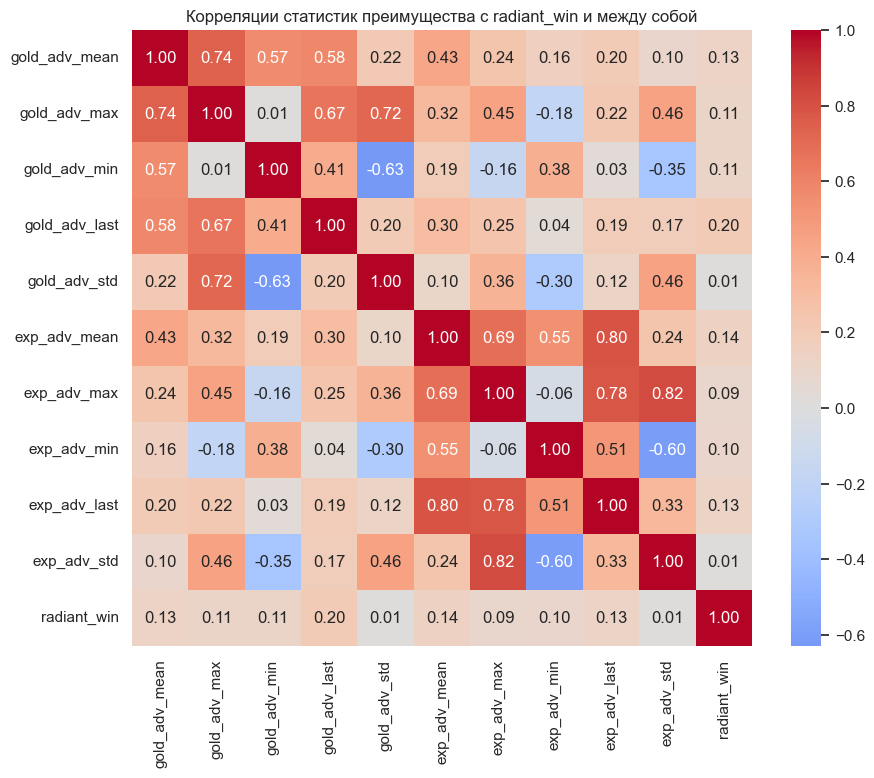

In [160]:
adv_features = adv_features.merge(train[["match_id", "radiant_win"]], on="match_id", how="left")

corr_matrix = adv_features.drop(columns="match_id").corr()

plt.figure(figsize=(10, 8))
sns.heatmap(corr_matrix, annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Корреляции статистик преимущества с radiant_win и между собой")
plt.show()

Корреляция в таргетом довольно слабая

gold_adv_mean, gold_adv_last, exp_adv_mean, exp_adv_last имеют наиболее сильную корреляцию с таргетом

gold_adv_mean, gold_adv_max, gold_adv_min, gold_adv_last имеют сильную корреляцию -- нужно оставить один во избежание мультиколлинеарности

то же самое с exp_adv_mean, exp_adv_max, exp_adv_last, exp_adv_min - наибольшая корреляция с таргетом у exp_adv_mean, поэтому оставим его

у exp_adv_std тоже низкая корр с таргетом - не оставляем


In [118]:
match_stats['gold_len'] = match_stats['gold_adv_list'].apply(len)
match_stats['exp_len'] = match_stats['exp_adv_list'].apply(len)
invalid_gold = match_stats[match_stats['gold_len'] != 16]
invalid_exp = match_stats[match_stats['exp_len'] != 16]
print(f"\nМатчей с gold_adv != 16: {len(invalid_gold)}")
print(f"Матчей с exp_adv != 16: {len(invalid_exp)}")


Матчей с gold_adv != 16: 0
Матчей с exp_adv != 16: 0


In [166]:
adv_features

,match_id,gold_adv_mean,gold_adv_max,gold_adv_min,gold_adv_last,gold_adv_std,exp_adv_mean,exp_adv_max,exp_adv_min,exp_adv_last,exp_adv_std,radiant_win
0,1340959379,0.0000,0,0,0,0.000000,0.0,0,0,0,0.00000,True
1,1377521758,0.0000,0,0,0,0.000000,0.0,0,0,0,0.00000,False
2,1457973639,0.0000,0,0,0,0.000000,0.0,0,0,0,0.00000,False
3,1629821522,0.0000,0,0,0,0.000000,0.0,0,0,0,0.00000,True
4,1529300845,808.5625,2969,0,2969,910.897015,-354.5,449,-1272,-1272,528.86364,False
...,...,...,...,...,...,...,...,...,...,...,...,...
767801,1601209593,0.0000,0,0,0,0.000000,0.0,0,0,0,0.00000,NaN
767802,1387531049,0.0000,0,0,0,0.000000,0.0,0,0,0,0.00000,False
767803,1615293881,0.0000,0,0,0,0.000000,0.0,0,0,0,0.00000,NaN
767804,1423370565,0.0000,0,0,0,0.000000,0.0,0,0,0,0.00000,True


In [190]:
train = train.merge(adv_features, on="match_id")
train.head(5)

,match_id,date,region,game_mode,duration,radiant_win_x,sqrt_duration,month,day,weekday,...,gold_adv_max,gold_adv_min,gold_adv_last,gold_adv_std,exp_adv_mean,exp_adv_max,exp_adv_min,exp_adv_last,exp_adv_std,radiant_win_y
0,1606558457,2024-01-01,3,1,50,True,7.071068,1,1,0,...,3308,-876,3308,1023.461267,967.8750,3033,0,3033,938.016449,True
1,1533104773,2024-01-01,3,1,86,True,9.273618,1,1,0,...,3851,0,3851,1069.915386,231.4375,1810,-2356,-339,1312.258262,True
2,1494396881,2024-01-01,3,1,211,True,14.525839,1,1,0,...,0,0,0,0.000000,0.0000,0,0,0,0.000000,True
3,1457581060,2024-01-01,3,1,270,True,16.431677,1,1,0,...,0,0,0,0.000000,0.0000,0,0,0,0.000000,True
4,1590242915,2024-01-01,3,21,318,True,17.832555,1,1,0,...,4286,0,3130,1322.132355,1866.6250,4075,0,4075,999.681566,True


In [227]:
adv_features = adv_features.drop(columns=["radiant_win"])

In [237]:
test = test.merge(adv_features[["match_id", "gold_adv_last", "exp_adv_mean"]], on="match_id", how="inner")
test

,match_id,date,region,game_mode,duration,sqrt_duration,month,is_weekend,is_new_year,is_ti_period,weekday_sin,weekday_cos,day_sin,day_cos,gold_adv_last,exp_adv_mean
0,1509410699,2024-12-14,6,22,2544.777223,50.445785,12,1,0,0,-0.974928,-0.222521,0.406737,-0.913545,0,0.0000
1,1307322096,2024-12-15,12,22,2538.530024,50.383827,12,1,0,0,-0.781831,0.623490,0.207912,-0.978148,0,0.0000
2,1427032882,2024-12-03,3,1,2603.879878,51.028226,12,0,0,0,0.781831,0.623490,0.406737,0.913545,-1271,1478.5625
3,1335981501,2024-12-29,3,1,2603.879878,51.028226,12,1,0,0,-0.781831,0.623490,-0.406737,0.913545,0,0.0000
4,1305100719,2024-12-23,3,22,2561.973977,50.615946,12,0,0,0,0.000000,1.000000,-0.994522,-0.104528,6012,-617.4375
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
60947,1356667203,2024-12-08,3,1,2603.879878,51.028226,12,1,0,0,-0.781831,0.623490,0.994522,0.104528,-1107,1019.4375
60948,1633554612,2024-12-12,3,1,2603.879878,51.028226,12,0,0,0,0.433884,-0.900969,0.743145,-0.669131,0,0.0000
60949,1431018719,2024-12-03,3,22,2561.973977,50.615946,12,0,0,0,0.781831,0.623490,0.406737,0.913545,2029,-514.3750
60950,1595824314,2024-12-10,6,4,2554.928739,50.546303,12,0,0,0,0.781831,0.623490,0.951057,-0.309017,0,0.0000


In [127]:
categorical = ["game_mode", "month"]
numeric = ["sqrt_duration", "region", "day_sin", "day_cos", "weekday_sin", "weekday_cos", "gold_adv_last", "exp_adv_mean"]
other = ["is_weekend", "is_new_year", "is_ti_period"]

X = train[categorical + numeric + other]
y = train["radiant_win"]

X_train, X_val, y_train, y_val = train_test_split(X, y, stratify=y, test_size=0.2, random_state=10)

X_train_enc = encoder.fit_transform(X_train, y_train)
X_val_enc = encoder.transform(X_val)

X_train['region'] = X_train_enc['region']
X_val['region'] = X_val_enc['region']

# Препроцессинг
preprocessor = ColumnTransformer([
    ("ohe", OneHotEncoder(handle_unknown="ignore", sparse_output=False), categorical),
    ("scale", RobustScaler(), numeric)
])

# Модель
model = Pipeline([
    ("prep", preprocessor),
    ("clf", LogisticRegression(max_iter=10000, random_state=10))
])

model.fit(X_train, y_train)
y_pred_proba = model.predict_proba(X_val)[:, 1]
print(f"gini = {gini(y_val, y_pred_proba)}")

gini = 0.8956732448771156


#### Задание 5.2. Тренд (0.75 балла)

Каждый уважающий себя лудоман знает, что 99% процентов игроков останавливается ровно перед тем, как сорвать джекпот. Так и здесь - если команда с треском проигрывает в первые 15 минут матча, возможно это признак камбека в следующие 50, как знать? Попробуем собрать агрегацию похитрее - она будет обозначать тренд, который есть в графиках преимущества, и если пословица верна, наша модель уловит эту зависимость.

<span style="color:grey"><font size="1">Администрация курса МО-1 категорически осуждает азартные игры, пример приводится сугубо в образовательных целях.</font></span>

Алгоритм действий:
1. Создать трансформер, который принимает на вход функцию агрегации.
2. Выделить тренд для обоих массивов `_adv` при помощи разных функций агрегаций. Попробуйте хотя бы два разных метода: разность первого и последнего значений, линейная регрессия, обученная методом МНК, нелинейная регрессия, что-то еще...
3. Добавьте хотя бы два соответствующих признака вашим трансформером (либо два разных метода, либо тренд для Radiant и тренд для Dire).
4. Проверьте, есть ли корреляция между признаком и таргетом.

In [136]:
# методы агрегации

def first_last_diff(series):
    if len(series) == 0:
        return 0
    return series[-1] - series[0]


def linear_regression(series):
    if len(series) < 2:
        return 0
    
    X = np.arange(len(series)).reshape(-1, 1)
    y = np.array(series)
    
    lr = LinearRegression()
    lr.fit(X, y)
    
    return lr.coef_[0]


def exponential_weighted(series, alpha=0.1):
    if len(series) < 2:
        return 0
    
    series_array = np.array(series)
    weights = np.array([alpha * (1 - alpha) ** (len(series) - 1 - i) for i in range(len(series))])
    weights = weights / weights.sum()
    
    weighted_diff = np.dot(weights, series_array) - series_array[0]
    
    return weighted_diff


def polynomial(series, degree=2):
    if len(series) < degree + 1:
        return 0
    
    X = np.arange(len(series))
    y = np.array(series)
    
    coeffs = np.polyfit(X, y, degree)
    
    return coeffs[0]


def momentum_indicator(series, window=6):
    if len(series) < window + 1:
        return 0
    
    series_array = np.array(series)
    recent = series_array[-window-1:]
    
    diffs = np.diff(recent)
    
    return np.mean(diffs)


def late_game_advantage(series, last_n_percent=0.3):
    if len(series) == 0:
        return 0
    
    n = max(1, int(len(series) * last_n_percent))
    return np.mean(series[-n:])


def early_game_advantage(series, first_n_percent=0.3):
    if len(series) == 0:
        return 0
    
    n = max(1, int(len(series) * first_n_percent))
    return np.mean(series[:n])


def comeback_indicator(series):
    if len(series) < 10:
        return 0
    
    third = len(series) // 3
    
    early = np.mean(series[:third])
    late = np.mean(series[-third:])
    
    return late - early

In [137]:
class TrendExtractor:

    def __init__(self, agg_func: Callable = None, feature_name: str = 'trend'):
        self.agg_func = agg_func if agg_func is not None else first_last_diff
        self.feature_name = feature_name

    def fit(self, X, y=None):
        pass

    def transform(self, X, y=None):
        X_copy = X.copy()
        for col in X_copy.columns:
            if X_copy[col].dtype == 'object':
                X_copy[f'{col}_{self.feature_name}'] = X_copy[col].apply(lambda x: self.agg_func(x))
        
        return X_copy

In [179]:
match_stats_trend = match_stats[["match_id", "gold_adv_list", "exp_adv_list"]].copy()

In [180]:
extractor_diff = TrendExtractor(agg_func=first_last_diff, feature_name='diff')
data_with_diff = extractor_diff.transform(match_stats_trend)

extractor_lr = TrendExtractor(agg_func=linear_regression, feature_name='lr_slope')
data_with_lr = extractor_lr.transform(match_stats_trend)

extractor_ewt = TrendExtractor(agg_func=exponential_weighted, feature_name='ewt')
data_with_ewt = extractor_ewt.transform(match_stats_trend)

extractor_poly = TrendExtractor(agg_func=polynomial, feature_name='poly_accel')
data_with_poly = extractor_poly.transform(match_stats_trend)

extractor_momentum = TrendExtractor(agg_func=momentum_indicator, feature_name='momentum')
data_with_momentum = extractor_momentum.transform(match_stats_trend)

extractor_comeback = TrendExtractor(agg_func=comeback_indicator, feature_name='comeback')
data_with_comeback = extractor_comeback.transform(match_stats_trend)

extractor_late = TrendExtractor(agg_func=late_game_advantage, feature_name='late_adv')
data_with_late = extractor_late.transform(match_stats_trend)

extractor_early = TrendExtractor(agg_func=early_game_advantage, feature_name='early_adv')
data_with_early = extractor_early.transform(match_stats_trend)

trend_features = match_stats_trend[['match_id']].copy()

for df, suffix in [
    (data_with_diff, '_diff'),
    (data_with_lr, '_lr'),
    (data_with_ewt, '_ewt'),
    (data_with_poly, '_poly'),
    (data_with_momentum, '_momentum'),
    (data_with_comeback, '_comeback'),
    (data_with_late, '_late_adv'),
    (data_with_early, '_early_adv')]:
    for col in df.columns:
        if col != 'match_id':
            trend_features[col] = df[col]

trend_features.head(5)

,match_id,gold_adv_list,exp_adv_list,gold_adv_list_diff,exp_adv_list_diff,gold_adv_list_lr_slope,exp_adv_list_lr_slope,gold_adv_list_ewt,exp_adv_list_ewt,gold_adv_list_poly_accel,exp_adv_list_poly_accel,gold_adv_list_momentum,exp_adv_list_momentum,gold_adv_list_comeback,exp_adv_list_comeback,gold_adv_list_late_adv,exp_adv_list_late_adv,gold_adv_list_early_adv,exp_adv_list_early_adv
0,1340959379,"[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0]","[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0]",0,0,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.0,0.0,0.0,0.0,0.0,0.00
1,1377521758,"[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0]","[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0]",0,0,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.0,0.0,0.0,0.0,0.0,0.00
2,1457973639,"[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0]","[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0]",0,0,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.0,0.0,0.0,0.0,0.0,0.00
3,1629821522,"[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0]","[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0]",0,0,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.0,0.0,0.0,0.0,0.0,0.00
4,1529300845,"[0, 334, 179, 655, 31, 1029, 1029, 1029, 662, ...","[0, 147, 105, -9, -651, -471, -471, -723, -441...",2969,-1272,119.207353,-41.852941,1104.467852,-447.638818,18.544293,0.188375,489.833333,-50.333333,1346.0,-248.6,1792.5,-525.0,292.0,60.75


In [181]:
trend_features = trend_features.drop(columns=["gold_adv_list", "exp_adv_list"])

In [192]:
trend_features

,match_id,gold_adv_list_diff,exp_adv_list_diff,gold_adv_list_lr_slope,exp_adv_list_lr_slope,gold_adv_list_ewt,exp_adv_list_ewt,gold_adv_list_poly_accel,exp_adv_list_poly_accel,gold_adv_list_momentum,exp_adv_list_momentum,gold_adv_list_comeback,exp_adv_list_comeback,gold_adv_list_late_adv,exp_adv_list_late_adv,gold_adv_list_early_adv,exp_adv_list_early_adv
0,1340959379,0,0,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.0,0.0,0.0,0.0,0.0,0.00
1,1377521758,0,0,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.0,0.0,0.0,0.0,0.0,0.00
2,1457973639,0,0,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.0,0.0,0.0,0.0,0.0,0.00
3,1629821522,0,0,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.0,0.0,0.0,0.0,0.0,0.00
4,1529300845,2969,-1272,119.207353,-41.852941,1104.467852,-447.638818,18.544293,0.188375,489.833333,-50.333333,1346.0,-248.6,1792.5,-525.0,292.0,60.75
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
767829,1601209593,0,0,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.0,0.0,0.0,0.0,0.0,0.00
767830,1387531049,0,0,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.0,0.0,0.0,0.0,0.0,0.00
767831,1615293881,0,0,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.0,0.0,0.0,0.0,0.0,0.00
767832,1423370565,0,0,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.0,0.0,0.0,0.0,0.0,0.00


In [193]:
train = train.merge(trend_features, on='match_id')
train.head(5)

,match_id,date,region,game_mode,duration,radiant_win,sqrt_duration,month,day,weekday,...,gold_adv_list_poly_accel,exp_adv_list_poly_accel,gold_adv_list_momentum,exp_adv_list_momentum,gold_adv_list_comeback,exp_adv_list_comeback,gold_adv_list_late_adv,exp_adv_list_late_adv,gold_adv_list_early_adv,exp_adv_list_early_adv
0,1606558457,2024-01-01,3,1,50,True,7.071068,1,1,0,...,29.401786,16.915966,480.166667,367.000000,1652.0,1941.2,1374.75,2382.75,-511.50,213.75
1,1533104773,2024-01-01,3,1,86,True,9.273618,1,1,0,...,13.423845,-29.723564,388.666667,-27.833333,2330.2,-2350.8,3041.00,-1483.50,499.00,851.75
2,1494396881,2024-01-01,3,1,211,True,14.525839,1,1,0,...,0.000000,0.000000,0.000000,0.000000,0.0,0.0,0.00,0.00,0.00,0.00
3,1457581060,2024-01-01,3,1,270,True,16.431677,1,1,0,...,0.000000,0.000000,0.000000,0.000000,0.0,0.0,0.00,0.00,0.00,0.00
4,1590242915,2024-01-01,3,21,318,True,17.832555,1,1,0,...,-4.754727,-4.769608,201.000000,350.000000,3195.8,1907.6,3890.25,2951.25,370.25,534.50


In [238]:
test = test.merge(trend_features[["match_id", "exp_adv_list_ewt", "gold_adv_list_momentum"]], on='match_id', how='inner')
test

,match_id,date,region,game_mode,duration,sqrt_duration,month,is_weekend,is_new_year,is_ti_period,weekday_sin,weekday_cos,day_sin,day_cos,gold_adv_last,exp_adv_mean,exp_adv_list_ewt,gold_adv_list_momentum
0,1509410699,2024-12-14,6,22,2544.777223,50.445785,12,1,0,0,-0.974928,-0.222521,0.406737,-0.913545,0,0.0000,0.000000,0.000000
1,1307322096,2024-12-15,12,22,2538.530024,50.383827,12,1,0,0,-0.781831,0.623490,0.207912,-0.978148,0,0.0000,0.000000,0.000000
2,1427032882,2024-12-03,3,1,2603.879878,51.028226,12,0,0,0,0.781831,0.623490,0.406737,0.913545,-1271,1478.5625,2141.789973,-117.333333
3,1335981501,2024-12-29,3,1,2603.879878,51.028226,12,1,0,0,-0.781831,0.623490,-0.406737,0.913545,0,0.0000,0.000000,0.000000
4,1305100719,2024-12-23,3,22,2561.973977,50.615946,12,0,0,0,0.000000,1.000000,-0.994522,-0.104528,6012,-617.4375,-878.447845,917.666667
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
60947,1356667203,2024-12-08,3,1,2603.879878,51.028226,12,1,0,0,-0.781831,0.623490,0.994522,0.104528,-1107,1019.4375,1223.578523,-392.166667
60948,1633554612,2024-12-12,3,1,2603.879878,51.028226,12,0,0,0,0.433884,-0.900969,0.743145,-0.669131,0,0.0000,0.000000,0.000000
60949,1431018719,2024-12-03,3,22,2561.973977,50.615946,12,0,0,0,0.781831,0.623490,0.406737,0.913545,2029,-514.3750,-527.295372,279.000000
60950,1595824314,2024-12-10,6,4,2554.928739,50.546303,12,0,0,0,0.781831,0.623490,0.951057,-0.309017,0,0.0000,0.000000,0.000000


In [194]:
train.columns

Index(['match_id', 'date', 'region', 'game_mode', 'duration', 'radiant_win',
       'sqrt_duration', 'month', 'day', 'weekday', 'is_weekend', 'is_new_year',
       'is_ti_period', 'weekday_sin', 'weekday_cos', 'day_sin', 'day_cos',
       'gold_adv_mean', 'gold_adv_max', 'gold_adv_min', 'gold_adv_last',
       'gold_adv_std', 'exp_adv_mean', 'exp_adv_max', 'exp_adv_min',
       'exp_adv_last', 'exp_adv_std', 'gold_adv_list_diff',
       'exp_adv_list_diff', 'gold_adv_list_lr_slope', 'exp_adv_list_lr_slope',
       'gold_adv_list_ewt', 'exp_adv_list_ewt', 'gold_adv_list_poly_accel',
       'exp_adv_list_poly_accel', 'gold_adv_list_momentum',
       'exp_adv_list_momentum', 'gold_adv_list_comeback',
       'exp_adv_list_comeback', 'gold_adv_list_late_adv',
       'exp_adv_list_late_adv', 'gold_adv_list_early_adv',
       'exp_adv_list_early_adv'],
      dtype='object')

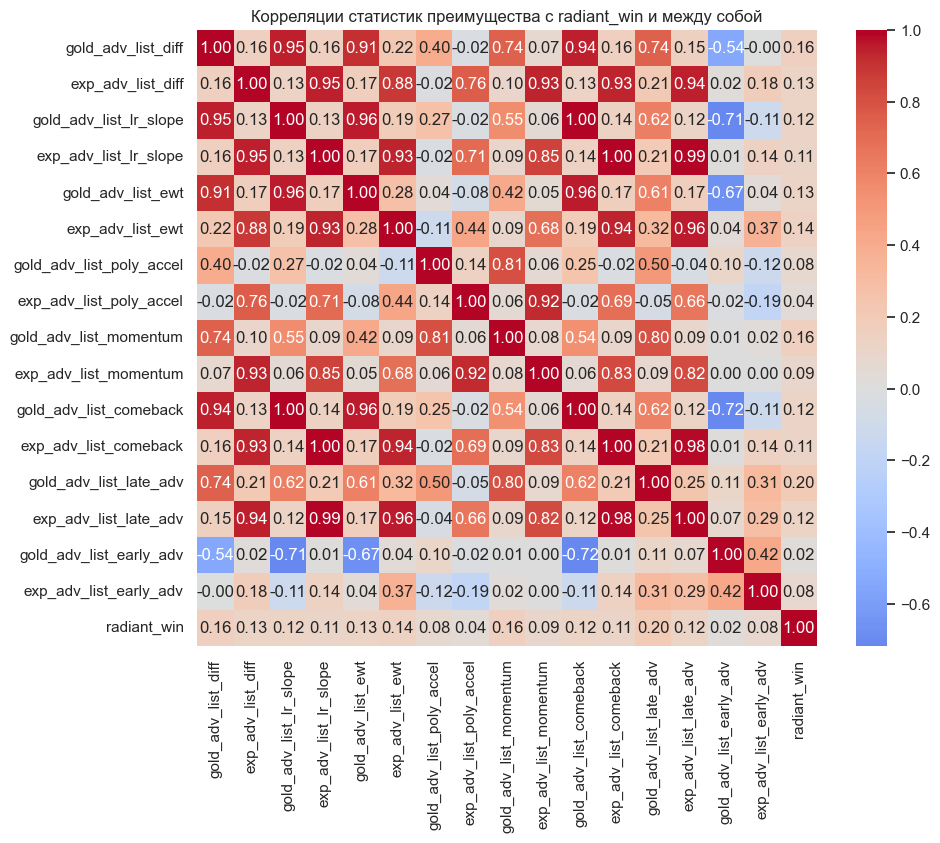

In [195]:
trend_features = trend_features.merge(train[["match_id", "radiant_win"]], on="match_id", how="left")

corr_matrix = trend_features.drop(columns="match_id").corr()

plt.figure(figsize=(10, 8))
sns.heatmap(corr_matrix, annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Корреляции статистик преимущества с radiant_win и между собой")
plt.show()

наибольшая корреляция с таргетом у 'gold_adv_list_diff', 'exp_adv_list_diff', 'gold_adv_list_ewt', 'exp_adv_list_ewt', 'gold_adv_list_momentum', 'gold_adv_list_late_adv'

при этом у всех методов агрегации xp высокая корреляция со всеми остальными (кроме early_adv) и то же самое для gold

поэтому выберем тот, у кого корреляция с таргетом выше: 'exp_adv_list_ewt' (экспонениально взвешенный тренд) и 'gold_adv_list_momentum' (средняя скорость изменения)


In [196]:
categorical = ["game_mode", "month"]
numeric = ["sqrt_duration", "region", "day_sin", "day_cos", "weekday_sin", "weekday_cos", "gold_adv_last", "exp_adv_mean", 
           "exp_adv_list_ewt", "gold_adv_list_momentum"]
other = ["is_weekend", "is_new_year", "is_ti_period"]

X = train[categorical + numeric + other]
y = train["radiant_win"]

X_train, X_val, y_train, y_val = train_test_split(X, y, stratify=y, test_size=0.2, random_state=10)

X_train_enc = encoder.fit_transform(X_train, y_train)
X_val_enc = encoder.transform(X_val)

X_train['region'] = X_train_enc['region']
X_val['region'] = X_val_enc['region']

# Препроцессинг
preprocessor = ColumnTransformer([
    ("ohe", OneHotEncoder(handle_unknown="ignore", sparse_output=False), categorical),
    ("scale", RobustScaler(), numeric)
])

# Модель
model = Pipeline([
    ("prep", preprocessor),
    ("clf", LogisticRegression(max_iter=10000, random_state=10))
])

model.fit(X_train, y_train)
y_pred_proba = model.predict_proba(X_val)[:, 1]
print(f"gini = {gini(y_val, y_pred_proba)}")

gini = 0.8960043980940835


#### Задание 5.3. Площадь под кривой и взаимодействие признаков (0.75 балла)

Скорее всего, признаки, что вы считали в предыдущих пунктах задействовали либо информацию по оси x, либо информацию по оси y, но никак не обе сразу. Один из способов попробовать учесть и то, и другое - комбинация признаков, например, можно взять и перемножить признаки между собой, либо взять и собрать кортеж из нескольких категориальных признаков. Кажется, что в пунктах с эмбеддингами и простейшим EDA это сделать совершенно не сложно, ведь признаки уже декомпозировано, а что насчет агрегаций?

Площадь под кривой, в зависимости от того, как ее считать, обладает кучей разных прикольных свойств, например, если считать ее по методу левых прямоугольников, графики, которые растут в начале, будут иметь больший скор, чем те, что растут в конце, и так далее.

Попробуем собрать трансформер поинтереснее:

1. Создать трансформер, который принимает на вход функцию интегрирования.
2. Выделить площадь для обоих массивов `_adv` при помощи двух разных функций интегрирования. Попробуйте хотя бы два разных метода: прямоугольников, трапеций, Симпсона, и т.д.
3. Добавьте хотя бы два признака (либо два метода, либо площадь для Radiant и Dire).
4. Проанализируйте самостоятельно, что важнее - преимущество в начале или в конце матча (таким образом у нас одновременно и зависимость по x, т.е. времени, и по y). Создайте кастомную функцию интегрирования (не метод прямоугольников), которая будет давать больший вест правому или левому хвосту. Добавьте этот признак.
5. Посмотрите, дает ли этот признак вклад в качество модели.

In [201]:
# методы интегрирования
from scipy import integrate
from scipy.integrate import trapezoid

def left_rectangles(series):
    if len(series) < 2:
        return 0
    return np.sum(series[:-1])


def right_rectangles(series):
    if len(series) < 2:
        return 0
    return np.sum(series[1:])


def trapezoidal(series):
    if len(series) < 2:
        return 0
    return trapezoid(series, dx=1)


def simpson(series):
    if len(series) < 3:
        return trapezoidal(series)
    
    return integrate.simpson(series)


# кастомные

def weighted_early_game(series, early_weight=2.0):
    if len(series) < 2:
        return 0
    
    early_cutoff = int(len(series) * 0.3)

    early_area = trapezoid(series[:early_cutoff]) * early_weight
    late_area = trapezoid(series[early_cutoff:])
    
    return early_area + late_area

def weighted_late_game(series, late_weight=3.0):
    if len(series) < 2:
        return 0
    
    late_cutoff = int(len(series) * 0.7)

    early_area = trapezoid(series[:late_cutoff])
    late_area = trapezoid(series[late_cutoff:]) * late_weight
    
    return early_area + late_area

In [202]:
class AreaUnderCurveExtractor:

    def __init__(self, integration_func: Callable = None, feature_name: str = 'auc'):
        self.integration_func = integration_func if integration_func is not None else trapezoidal
        self.feature_name = feature_name

    def transform(self, X, y=None):
        X_copy = X.copy()

        for col in X_copy.columns:
            if X_copy[col].dtype == 'object':
                X_copy[f'{col}_{self.feature_name}'] = X_copy[col].apply(lambda x: self.integration_func(x))
              
        return X_copy

In [ ]:
auc_features = match_stats[["match_id", "gold_adv_list", "exp_adv_list"]].copy()

methods = [
    ('left_rect', left_rectangles), # Левые прямоугольники (вес началу)
    ('right_rect', right_rectangles), # Правые прямоугольники (вес концу)
    ('trapz', trapezoidal), # Метод трапеций
    ('simpson', simpson), # Метод Симпсона
    ('early_weighted', weighted_early_game), # Взвешенная ранняя игра
    ('late_weighted', weighted_late_game) # Взвешенная поздняя игра
]

area_features = auc_features[['match_id']].copy()
for method_name, method_func in methods:
    extractor = AreaUnderCurveExtractor(integration_func=method_func, feature_name=method_name)
    result = extractor.transform(auc_features)

    for col in result.columns:
        if col != 'match_id':
            area_features[col] = result[col]
area_features

,match_id,gold_adv_list,exp_adv_list,gold_adv_list_left_rect,exp_adv_list_left_rect,gold_adv_list_right_rect,exp_adv_list_right_rect,gold_adv_list_trapz,exp_adv_list_trapz,gold_adv_list_simpson,exp_adv_list_simpson,gold_adv_list_early_weighted,exp_adv_list_early_weighted,gold_adv_list_late_weighted,exp_adv_list_late_weighted
0,1340959379,"[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0]","[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0]",0,0,0,0,0.0,0.0,0.000000,0.000000,0.0,0.0,0.0,0.0
1,1377521758,"[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0]","[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0]",0,0,0,0,0.0,0.0,0.000000,0.000000,0.0,0.0,0.0,0.0
2,1457973639,"[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0]","[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0]",0,0,0,0,0.0,0.0,0.000000,0.000000,0.0,0.0,0.0,0.0
3,1629821522,"[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0]","[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0]",0,0,0,0,0.0,0.0,0.000000,0.000000,0.0,0.0,0.0,0.0
4,1529300845,"[0, 334, 179, 655, 31, 1029, 1029, 1029, 662, ...","[0, 147, 105, -9, -651, -471, -471, -723, -441...",9968,-4400,12937,-5672,11452.5,-5036.0,12103.166667,-4941.583333,11950.0,-4458.5,23188.0,-7471.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
767829,1601209593,"[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0]","[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0]",0,0,0,0,0.0,0.0,0.000000,0.000000,0.0,0.0,0.0,0.0
767830,1387531049,"[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0]","[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0]",0,0,0,0,0.0,0.0,0.000000,0.000000,0.0,0.0,0.0,0.0
767831,1615293881,"[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0]","[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0]",0,0,0,0,0.0,0.0,0.000000,0.000000,0.0,0.0,0.0,0.0
767832,1423370565,"[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0]","[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0]",0,0,0,0,0.0,0.0,0.000000,0.000000,0.0,0.0,0.0,0.0


In [212]:
target_df = train[['match_id', 'radiant_win']].copy()
area_features = area_features.merge(target_df, on="match_id", how="inner")
area_features

,match_id,gold_adv_list,exp_adv_list,gold_adv_list_left_rect,exp_adv_list_left_rect,gold_adv_list_right_rect,exp_adv_list_right_rect,gold_adv_list_trapz,exp_adv_list_trapz,gold_adv_list_simpson,exp_adv_list_simpson,gold_adv_list_early_weighted,exp_adv_list_early_weighted,gold_adv_list_late_weighted,exp_adv_list_late_weighted,radiant_win
0,1340959379,"[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0]","[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0]",0,0,0,0,0.0,0.0,0.000000,0.000000,0.0,0.0,0.0,0.0,True
1,1377521758,"[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0]","[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0]",0,0,0,0,0.0,0.0,0.000000,0.000000,0.0,0.0,0.0,0.0,False
2,1457973639,"[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0]","[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0]",0,0,0,0,0.0,0.0,0.000000,0.000000,0.0,0.0,0.0,0.0,False
3,1629821522,"[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0]","[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0]",0,0,0,0,0.0,0.0,0.000000,0.000000,0.0,0.0,0.0,0.0,True
4,1529300845,"[0, 334, 179, 655, 31, 1029, 1029, 1029, 662, ...","[0, 147, 105, -9, -651, -471, -471, -723, -441...",9968,-4400,12937,-5672,11452.5,-5036.0,12103.166667,-4941.583333,11950.0,-4458.5,23188.0,-7471.0,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
709916,1497074452,"[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0]","[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0]",0,0,0,0,0.0,0.0,0.000000,0.000000,0.0,0.0,0.0,0.0,False
709917,1392172798,"[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0]","[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0]",0,0,0,0,0.0,0.0,0.000000,0.000000,0.0,0.0,0.0,0.0,True
709918,1387531049,"[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0]","[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0]",0,0,0,0,0.0,0.0,0.000000,0.000000,0.0,0.0,0.0,0.0,False
709919,1423370565,"[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0]","[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0]",0,0,0,0,0.0,0.0,0.000000,0.000000,0.0,0.0,0.0,0.0,True


In [ ]:
early_corr_xp = area_features['exp_adv_list_early_weighted'].corr(area_features['radiant_win'])
late_corr_xp = area_features['exp_adv_list_late_weighted'].corr(area_features['radiant_win'])

early_corr_gold = area_features['gold_adv_list_early_weighted'].corr(area_features['radiant_win'])
late_corr_gold = area_features['gold_adv_list_late_weighted'].corr(area_features['radiant_win'])

print(f"xp взвешенная ранняя игра: {early_corr_xp:.4f}")
print(f"xp взвешенная поздняя игра: {late_corr_xp:.4f}")
print(f"разница: {abs(late_corr_xp) - abs(early_corr_xp):.4f}")
print()
print(f"gold взвешенная ранняя игра: {early_corr_gold:4f}")
print(f"gold взвешенная поздняя игра: {late_corr_gold:.4f}")
print(f"разница: {abs(late_corr_gold) - abs(early_corr_gold):.4f}")

xp взвешенная ранняя игра: 0.1386
xp взвешенная поздняя игра: 0.1340
разница: -0.0046

gold взвешенная ранняя игра: 0.111613
gold взвешенная поздняя игра: 0.1691
разница: 0.0574


для опыта получается раняя игра важнее (но незначительно), а для золота наоборот

In [216]:
def exponential_decay_weight(series, decay_rate=0.05):
    if len(series) < 2:
        return 0
    
    n = len(series)
    weights = np.exp(decay_rate * np.arange(n))
    weighted_sum = np.sum(series * weights)
    
    return weighted_sum

In [217]:
extractor_exp = AreaUnderCurveExtractor(
    integration_func=exponential_decay_weight, 
    feature_name='exp_late_weighted'
)

exp_area_features = extractor_exp.transform(auc_features)
area_features = area_features.merge(
    exp_area_features[['match_id', 'gold_adv_list_exp_late_weighted', 'exp_adv_list_exp_late_weighted']],
    on='match_id')

In [220]:
area_features = area_features.drop(columns=["gold_adv_list", "exp_adv_list"])

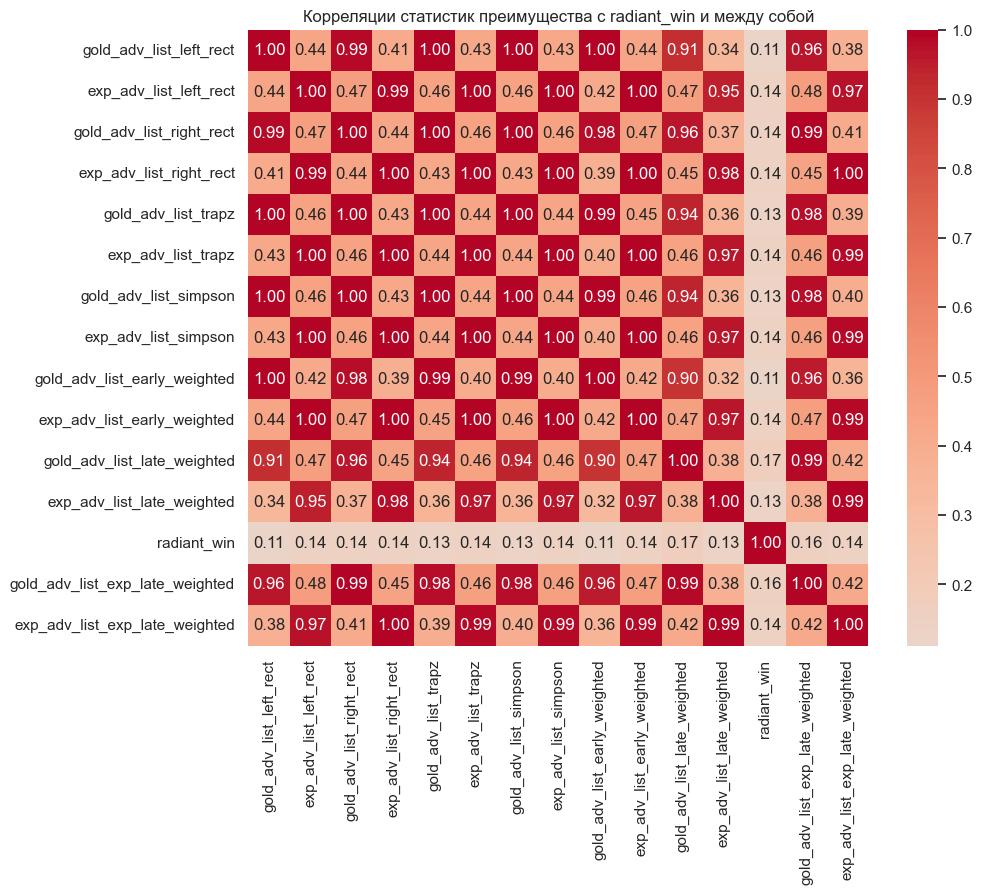

In [221]:
corr_matrix = area_features.drop(columns="match_id").corr()

plt.figure(figsize=(10, 8))
sns.heatmap(corr_matrix, annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Корреляции статистик преимущества с radiant_win и между собой")
plt.show()

In [222]:
train = train.merge(area_features[["match_id", "gold_adv_list_exp_late_weighted", "exp_adv_list_exp_late_weighted"]], on="match_id", how="inner")
train.head(5)

,match_id,date,region,game_mode,duration,radiant_win,sqrt_duration,month,day,weekday,...,gold_adv_list_momentum,exp_adv_list_momentum,gold_adv_list_comeback,exp_adv_list_comeback,gold_adv_list_late_adv,exp_adv_list_late_adv,gold_adv_list_early_adv,exp_adv_list_early_adv,gold_adv_list_exp_late_weighted,exp_adv_list_exp_late_weighted
0,1606558457,2024-01-01,3,1,50,True,7.071068,1,1,0,...,480.166667,367.000000,1652.0,1941.2,1374.75,2382.75,-511.50,213.75,5393.042063,27848.807652
1,1533104773,2024-01-01,3,1,86,True,9.273618,1,1,0,...,388.666667,-27.833333,2330.2,-2350.8,3041.00,-1483.50,499.00,851.75,42926.122277,203.754891
2,1494396881,2024-01-01,3,1,211,True,14.525839,1,1,0,...,0.000000,0.000000,0.0,0.0,0.00,0.00,0.00,0.00,0.000000,0.000000
3,1457581060,2024-01-01,3,1,270,True,16.431677,1,1,0,...,0.000000,0.000000,0.0,0.0,0.00,0.00,0.00,0.00,0.000000,0.000000
4,1590242915,2024-01-01,3,21,318,True,17.832555,1,1,0,...,201.000000,350.000000,3195.8,1907.6,3890.25,2951.25,370.25,534.50,56711.026536,49002.733127


In [ ]:
test = test.merge(area_features[["match_id", "gold_adv_list_exp_late_weighted", "exp_adv_list_exp_late_weighted"]], on="match_id", how="inner")

In [223]:
categorical = ["game_mode", "month"]
numeric = ["sqrt_duration", "region", "day_sin", "day_cos", "weekday_sin", "weekday_cos", "gold_adv_last", "exp_adv_mean", 
           "exp_adv_list_ewt", "gold_adv_list_momentum", "gold_adv_list_exp_late_weighted", "exp_adv_list_exp_late_weighted"]
other = ["is_weekend", "is_new_year", "is_ti_period"]

X = train[categorical + numeric + other]
y = train["radiant_win"]

X_train, X_val, y_train, y_val = train_test_split(X, y, stratify=y, test_size=0.2, random_state=10)

X_train_enc = encoder.fit_transform(X_train, y_train)
X_val_enc = encoder.transform(X_val)

X_train['region'] = X_train_enc['region']
X_val['region'] = X_val_enc['region']

# Препроцессинг
preprocessor = ColumnTransformer([
    ("ohe", OneHotEncoder(handle_unknown="ignore", sparse_output=False), categorical),
    ("scale", RobustScaler(), numeric)
])

# Модель
model = Pipeline([
    ("prep", preprocessor),
    ("clf", LogisticRegression(max_iter=10000, random_state=10))
])

model.fit(X_train, y_train)
y_pred_proba = model.predict_proba(X_val)[:, 1]
print(f"gini = {gini(y_val, y_pred_proba)}")

gini = 0.8982568710743155


/Users/ssonyii/Downloads/.conda/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


Поскольку статистики по героям на тестовой выборке нет, то нужно ее предсказать на train

### **Задание 6. High tech. Low life (1 балл)** <img height=25px align="center" src="https://media1.tenor.com/m/72ScVNgTGpYAAAAC/kaneki-tokyo-ghoul.gif"></img>

Иногда, вместо того, чтобы думать, тратить свои когнитивные ресурсы, что-то анализировать и решать, хочется скинуть свою работу на кого-то другого, что, в целом, вполне разумно. Также и мы можем пойти по пути наименьшего сопротивления и попросить придумать фичи за нас, звучит крайне соблазнительно, а вот полезно ли - совсем другой вопрос.

#### Задание 6.1. Автогенерация признаков (0.5 балла)

В сети Интернет находится множество инструментов для автоматической генерации признаков. Как правило, они не приносят такого же значимого эффекта, как ручная генерация, посколько знания домена и области в библиотеки не запихнешь, но попробовать всегда можно.

Задача:
1. Изучить туториалы из библиотеки [`featuretools`](https://featuretools.alteryx.com/en/stable).
2. Собрать 2-3 признака при помощи DFS или любого другого генератора.
3. Замерить качество и задуматься, зачем нужна эта домашка.

In [ ]:
# ヾ(⌐■_■)ノ♪ your code here

#### Задание 6.2. Нейросетевые признаки (0.5 балла)

Если вы следите за новостями, то вы, наверное, заметили, что в последнее время появилась такая модная и хайповая вещь, как большие языковые модели. Злые языки утверждают, что обычному работяге фит предиктору не место в мире будущего, где господствует ИИ. Давайте в этом (раз)убедимся.

Попробуйте:
1. Спросить у вашей любимой нейросети, какие признаки она может для вас придумать. Можете опираться на пункты выше, можете придумать что-то свое. Но помните, что как говорится, какой стол, такой и стул, поэтому пишите промпты с умом.
2. Показать, что нейросеть вам посоветовала, и реализовать это
3. Проанализировать результат и сделать твердый и четкий вывод, заменят ли нас LLM-ки.

In [ ]:
# ヾ(⌐■_■)ノ♪ your code here

### Заключение

Чтобы победить в соревновании, вам может понадобиться куда большее количество признаков. Не стесняйтесь гуглить, масштабировать пункты выше, например, эмбеддинги, пробовать применять те же техники, но к другим признакам, пробовать разные схемы валидации, тюнить в конце концов. Единого рецепта для лучшего решения задачи, увы, не существует, это горькая правда всего машинного обучения

In [ ]:
# ваши впечатления от задания

### А теперь об оценивании

Каждая из задач в ноутбуке имеет свою стоимость (указана в скобках рядом с задачей). При этом важно уточнить разницу между баллами за ноутбук и дополнительными баллами за позицию на приватном лидерборде в соревновании на Kaggle:

1. **Максимум за код/ноутбук — 8.0 баллов.**
   То есть, независимо от суммарной теоретической суммы всех подпунктов в тексте задания, за реализацию в ноутбуке можно получить не более 8 баллов.

2. **Максимально возможная оценка за всю работу — 11.0 баллов.**
   Остальные до 3.0 баллов начисляются за результаты в соревновании на Kaggle (лидерборд), при выполненном и загруженном в систему Anytask ноутбуке.

Баллы за сореву состоят из двух частей: процентильный бонус (до 2.0 баллов) и бонус за попадание в топ-10 (до 1.0 балла). Суммарный вклад соревнования не может превышать 3.0 баллов.

**A. Процентильный балл (не суммируется):**

* Если вы обогнали ≥ 90% участников (т.е. попали в топ 10%) — +2.0 балла.
* Если вы обогнали ≥ 60% участников — +1.5 балла.
* Если вы обогнали ≥ 30% участников — +1.0 балла.
* Если вы обогнали ≥ 10% участников — +0.5 балла.

**B. Балл за попадание в топ-10 (дополнительно):**

* 1-е место — +1.00 балла
* 2-е–3-е место — +0.75 балла
* 4-е–7-е место — +0.50 балла
* 8-е–10-е место — +0.25 балла

Пример расчёта

* Вы сделали ноутбук и получили за него 7.0 / 8.0.
* На лидерборде вы, зайка, обогнали 10% участников → процентильный бонус +2.0.
* Ваша позиция — 3-е место → топ-10 бонус +0.75.
* Итого: 7.0 + 2.0 + 0.75 = 9.75.

**Требование к воспроизводимости**

Баллы за соревнование начисляются **только** при наличии готового, полностью воспроизводимого пайплайна, который подтверждает результат лучшего сабмита. Такое решение нужно сдавать вместе с ноутбуком и своим ников в kaggle в Anytask ассистенту. Пайплайн должен выполнять всё автоматически при запуске ноутбука: при последовательном исполнении всех ячеек ноутбука (без ручных вмешательств) он должен воспроизвести предобработку, обучение/инференс и сгенерировать итоговый CSV-файл с прогнозами, используемый для сабмита. Среда запуска - colab.